**Change log · Letrozole NMF + PrefixSpan (fused)**

- **v1-v3** `Day1_nmf_v*`, `Day3_prefixspan_v*`  
  Separate Day 1 / Day 3 notebooks (untouched).
- **full** `Letrozole_NMF_PrefixSpan_full` (2026-10-09)  
  Part A = Day 1 (NMF), Part B = Day 3 (PrefixSpan); all events of each patient, no window.
- **agesex** `Letrozole_NMF_PrefixSpan_agesex_<mode>` (2026-10-28) ← **this notebook**  
  Chest pain sensitivity on letrozole (all women: age only): `AGE_SEX_CROSS` modes, Part A+ / A++, ladder; copies in `age_sex_sensitivity/`.

*The Part A narrative cells (sections 0 to 6) describe the `..._full` run; this run's component names are in `DESCR`.*

# Letrozole · NMF bundles — does age and sex at exposure change them? (sensitivity)

**Part A (Day 1)**: events, bag of codes, NMF (k from the stability sweep), loadings, NMF-bundles table, components JSON, then **Part A+** (what age and sex changed) and **Part A++** (do the sex and age loadings differ between components).
**Part B (Day 3)**: PrefixSpan motifs per bundle, stability, comparison groups, trajectory graph, final table, then a ladder of the four matrices.

Set `AGE_SEX_CROSS` (`'plain'`, `'crossed'`, `'both'`, `'extended'`), `WINDOW_MONTHS`, `CODESETS_FILE`, `TOKEN_LEVEL` and (optionally) `K_OVERRIDE` in the next cell, plus `SMOKE`, the weights `W_S` and `W_D`, and `AGE_EDGES`.
`TOKEN_LEVEL='concept'` is the token of `Letrozole_NMF_PrefixSpan_full` (one token per concept), so the `'plain'` copy should reproduce `nmf_k7_letrozole_full.npz`.

Its siblings sit in the same folder with the same cells; only the `AGE_SEX_CROSS` line differs. Every file a copy writes carries the mode in its name (`..._letrozole_agesex_<mode>`), so the four NMF runs can be read side by side. Paths: inputs, sql, helpers, codesets and the `..._full` fit are one folder up.

In [1]:
AGE_SEX_CROSS = 'both'  # what the bag of codes holds: 'plain' = only the plain codes (the Letrozole_NMF_PrefixSpan_full matrix) | 'crossed' = only crossed features, every code x sex x age band AT THE EVENT ('clomiphene_F_25-34') | 'both' = plain + crossed | 'extended' = plain + the patient's age band AT EACH letrozole exposure (every recurrent exposure lights its own band), one-hot, no crossing (weight W_D); the sex column is dropped when every patient has the same sex (this cohort: all women)
assert AGE_SEX_CROSS in ('plain', 'crossed', 'both', 'extended'), AGE_SEX_CROSS
VARIANT       = f'agesex_{AGE_SEX_CROSS}'   # label in TAG, the npz, the components json and both xlsx; it carries the AGE_SEX_CROSS mode so the four runs never overwrite each other ('full' is the Letrozole_NMF_PrefixSpan_full run, one folder up)
WINDOW_MONTHS = None        # applied right after tagging (ethos_omop.window_around_anchor); None = every event of each person
K_OVERRIDE    = None       # None = the k chosen by the stability sweep; set an int (e.g. 7) to force it
CODESETS_FILE = 'codesets.yaml'      # the letrozole codesets, one folder up
TOKEN_LEVEL   = 'concept'   # 'concept': one token per concept (as Letrozole_NMF_PrefixSpan_full) | 'group': a codeset tag is the NMF token (curated concepts collapse)
ANCHOR        = 'letrozole'
COHORT        = 'letrozole'
TAG           = f"{COHORT}_{VARIANT}"      # used in every cache / json / xlsx file name
assert TOKEN_LEVEL in ('group', 'concept'), TOKEN_LEVEL

# ---- new in this notebook: age at exposure and sex
SMOKE         = False      # True: 5,000 random patients, a short k grid and few refits, to see the whole notebook run in minutes (the cohort has 5,238 patients, so this is almost all of it)
SMOKE_N       = 5_000
PLAIN = AGE_SEX_CROSS in ('plain', 'both', 'extended')      # the bag has the plain columns
CROSS = AGE_SEX_CROSS in ('crossed', 'both')                # the bag has the crossed columns (one extra pass over the events)
DEMO  = AGE_SEX_CROSS == 'extended'                        # the matrix has the age band columns (and a sex column when the cohort has more than one sex), never crossed with a code
W_S           = 1.0        # value of the 0/1 crossed columns when plain + crossed are fitted together ('both'); a scale does not change a crossed-only fit
W_D           = 0.5        # value of the 0/1 age band columns in 'extended'. At 1.0 they are among the commonest columns and tend to take components of their own (chest pain, first round); lower it to let them join the care bundles
AGE_EDGES     = (25, 35, 45, 55, 65)   # 10-year bands: '<25', '25-34', '35-44', '45-54', '55-64', '65+' (the same as the chest pain notebooks; check the tails in 5b). (25, 30, ..., 65) gives the Census 5-year bands, tuple(range(0, 90, 5)) the plain ones
if SMOKE and K_OVERRIDE is None:
    K_OVERRIDE = 7          # a 5,000 patient sweep is too noisy to pick k

# Part A · Day 1 — NMF bundles

## 0 · Getting the data

**Goal:** pull every letrozole-exposed patient's medical history out of the data warehouse and save it to disk as plain files, so the rest of the notebook runs offline and reproducibly, without hitting Snowflake every time.

`ethos_omop.extract_cohort()` pulls the letrozole-exposure cohort: any patient with a letrozole drug exposure, defined in `sql/letrozole_cohort.sql`. It dumps the same shape `extract_omop()` does — `master_*` as the source of truth, `ethos_dip` excluded on both `concept_id` and `source_concept_id` for every domain table, standard-named symlinks for `meds_etl_omop`, plus:

* **`concept.csv` slimmed** to the concept_ids the cohort actually references, instead of the full multi-million-row table.
* **`concept_ancestor` dumped too**, restricted to rows touching the cohort — needed for ontology rollup (drug products to ingredients, unspecified diagnoses to their parents).

*In plain terms: this is a one-time data export, like running a big report and saving the results as spreadsheets (CSV files) in a folder. Every cell below reads from that folder, not from Snowflake directly.*

```python
import ethos_omop as eo
eo.extract_cohort("../../../sql/letrozole_cohort.sql")   # -> ../../../inputs/letrozole_cohort/
```

The next cell runs this once and skips it on every re-run once `../../../inputs/letrozole_cohort/` exists.

**No Snowflake access, or want to see the notebook run against data whose right answer you already know?** Use the synthetic demo extract instead:

```bash
python make_demo_extract.py 2000
```

The demo extract has the **same schema** — integer `concept_id`s resolved through `concept.csv`, `master_*` table names, the symlinks — plus a `truth.csv` giving each patient's planted trajectory archetype. Real extracts have no `truth.csv`. That absence is the whole problem this course is about, and every notebook here works either way.

In [2]:
import os, sys
sys.path.insert(0, '..')       # ethos_omop.py and the codesets live one folder up
import ethos_omop as eo

OUT_DIR     = "../../../inputs/letrozole_cohort/"                      # extract_cohort() output, relative to age_sex_sensitivity/
COHORT_SQL  = "../../../sql/letrozole_cohort.sql"   # relative to this notebook's cwd

# Runs once: if OUT_DIR is already populated, notebooks load from disk and never
# re-hit Snowflake. Delete OUT_DIR (or pick a different one) to force a re-pull.
if not os.path.isdir(OUT_DIR):
    eo.extract_cohort(COHORT_SQL, out_dir=OUT_DIR)
else:
    print(f"{OUT_DIR}/ already populated -- skipping extract_cohort(). "
          f"Delete it to re-pull from Snowflake.")

../../../inputs/letrozole_cohort// already populated -- skipping extract_cohort(). Delete it to re-pull from Snowflake.


### v2 · Visit pruning (care-driven bias)

The bundles from v1 reflect **care delivery, not condition**: pharmacy, office and ED visits are the
most common tokens and pull unrelated patients together. v2 changes one thing, at the load step
below: every event whose `domain` or `vocabulary_id` is "visit" is dropped before tagging.
Everything after it is unchanged, so v1 and v2 results are directly comparable.

Side effects to expect: the `ed_visit` codeset tag disappears (it sits on visit concepts), the
Table 1 `ed_visit` row reads 0%, and the proxy lookback window can shrink for patients whose first or
last record was a visit. The NMF fit is saved as `nmf_k{k}_letrozole_v2.npz`, so v1's file (which
the Day 3 notebook loads) is not overwritten.

In [3]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.width', 150); pd.set_option('display.max_columns', 40)

DOMAINS = ['Visit', 'Condition', 'Drug', 'Procedure', 'Measurement']   # Visit stays in the load so we can show before vs after

concept  = eo.load_concept(OUT_DIR)
eo.CODESETS = eo._load_codesets(os.path.join('..', CODESETS_FILE))   # eo.CODESETS is read at call time by build_codesets and by the concept-set cells below
codesets = eo.build_codesets(concept, verbose=True)
raw      = eo.load_events(OUT_DIR, domains=DOMAINS)
person   = eo.load_person(OUT_DIR)
truth    = eo.load_truth(OUT_DIR)                   # None against real data

# v2: drop every visit event BEFORE tagging (care-driven bias). A visit row is any row whose
# domain OR vocabulary is "visit"; pharmacy / office / ED visits otherwise dominate the bundles.
is_visit = (raw['domain'].astype(str).str.lower().eq('visit')
            | raw['vocabulary_id'].astype(str).str.lower().eq('visit'))
visits   = raw[is_visit]
events   = eo.tag_events(raw[~is_visit].reset_index(drop=True), codesets, token_level=TOKEN_LEVEL, multi_group=True)

# ---- before / after pruning
tbl = (pd.DataFrame({'before': raw['domain'].value_counts(), 'after': events['domain'].value_counts()})
         .fillna(0).astype(int))
tbl.loc['TOTAL'] = [len(raw), len(events)]
tbl['removed_%'] = ((1 - tbl['after'] / tbl['before']) * 100).round(1)
print("events per domain, BEFORE vs AFTER visit pruning")
print(tbl.to_string())
print(f"\npatients:               {raw.person_id.nunique():>10,} -> {events.person_id.nunique():,}")
print(f"distinct concepts:      {raw.concept_id.nunique():>10,} -> {events.concept_id.nunique():,}")
print(f"median events/patient:  {raw.groupby('person_id').size().median():>10,.0f} -> "
      f"{events.groupby('person_id').size().median():,.0f}")
print("\nremoved rows by vocabulary:")
print(visits['vocabulary_id'].value_counts().head(10).to_string())
print("\ntop removed visit concepts:")
print(visits['concept_name'].value_counts().head(10).to_string())

visit_ids = set(visits['concept_id'])
lost      = sorted(t for t, ids in codesets.items() if set(ids) & visit_ids)
print("\ncurated codeset tags that sit on visit concepts (their events are gone):", lost or "none")
vanished  = set(raw['person_id']) - set(events['person_id'])
if vanished:
    print(f"WARNING: {len(vanished):,} patients had only visit events and are no longer in `events`")
if not eo.group_mask(events, ANCHOR).any():
    print(f"WARNING: the cohort anchor `{ANCHOR}` has no events after pruning")
del raw, visits                                      # free memory; `events` is the pruned stream from here on

print(f"\nevents {events.shape}   patients {events.person_id.nunique()}")
print(f"codeset coverage: {events.in_codeset.mean():.1%} of events carry a clinical tag")
print(f"truth labels: {'present (DEMO extract)' if truth is not None else 'ABSENT (real data)'}")
events.head(6)


letrozole            2 concepts   e.g. ['letrozole 2.5 MG Oral Tablet', 'letrozole 2.5 MG Oral Tablet [Femara]']
anastrozole          1 concepts   e.g. ['anastrozole 1 MG Oral Tablet']
exemestane           1 concepts   e.g. ['exemestane 25 MG Oral Tablet']
tamoxifen            2 concepts   e.g. ['tamoxifen 10 MG Oral Tablet', 'tamoxifen 20 MG Oral Tablet']
clomiphene           3 concepts   e.g. ['clomiphene citrate 50 MG Oral Tablet', 'clomiphene citrate 50 MG Oral Tablet [Clomid]']
gonadotropin_drug    14 concepts   e.g. ['0.36 ML follitropin beta 833 UNT/ML Cartridge [Follistim]', '0.48 ML follitropin alfa 625 UNT/ML Pen Injector [Gonal F]']
art_procedure       23 concepts   e.g. ['Anesthesia for vaginal procedures (including biopsy of labia, vagina, cervix or endometrium); hysteroscopy and/or hysterosalpingography', 'Catheterization and introduction of saline or contrast material for saline infusion sonohysterography (SIS) or hysterosalpingography']
follicle_monitoring     1 concept

events per domain, BEFORE vs AFTER visit pruning
              before    after  removed_%
domain                                  
Condition     458033   458033        0.0
Drug          523552   523552        0.0
Measurement   339167   339167        0.0
Procedure     390455   390455        0.0
Visit         709880        0      100.0
TOTAL        2421087  1711207       29.3

patients:                    5,238 -> 5,238
distinct concepts:          11,008 -> 11,001
median events/patient:         328 -> 215

removed rows by vocabulary:
vocabulary_id
NUCC      516555
Visit     191934
SNOMED      1391

top removed visit concepts:
concept_name
Pharmacy                              516555
Office Visit                          164763
Telehealth                             18916
Home Visit                              8175
Unknown                                 1391
Pharmacy visit                            78
Emergency Room and Inpatient Visit         2

curated codeset tags that sit on visit 


events (1711207, 13)   patients 5238
codeset coverage: 8.9% of events carry a clinical tag
truth labels: ABSENT (real data)


,person_id,concept_id,event_date,domain,vocabulary_id,concept_code,concept_name,concept_class_id,token,group,groups,in_codeset,tag
0,1949,40223740,2019-07-01,Drug,RxNorm,999717,potassium nitrate 0.05 MG/MG / sodium fluoride...,Branded Drug,RxNorm/999717,NaN,NaN,False,potassium_nitrate_00__branded_drug__40223740
1,1949,40223740,2019-07-01,Drug,RxNorm,999717,potassium nitrate 0.05 MG/MG / sodium fluoride...,Branded Drug,RxNorm/999717,NaN,NaN,False,potassium_nitrate_00__branded_drug__40223740
2,1949,40223740,2019-09-25,Drug,RxNorm,999717,potassium nitrate 0.05 MG/MG / sodium fluoride...,Branded Drug,RxNorm/999717,NaN,NaN,False,potassium_nitrate_00__branded_drug__40223740
3,1949,40223740,2019-09-25,Drug,RxNorm,999717,potassium nitrate 0.05 MG/MG / sodium fluoride...,Branded Drug,RxNorm/999717,NaN,NaN,False,potassium_nitrate_00__branded_drug__40223740
4,1949,40223740,2019-12-27,Drug,RxNorm,999717,potassium nitrate 0.05 MG/MG / sodium fluoride...,Branded Drug,RxNorm/999717,NaN,NaN,False,potassium_nitrate_00__branded_drug__40223740
5,1949,40223740,2019-12-27,Drug,RxNorm,999717,potassium nitrate 0.05 MG/MG / sodium fluoride...,Branded Drug,RxNorm/999717,NaN,NaN,False,potassium_nitrate_00__branded_drug__40223740


In [4]:
if WINDOW_MONTHS:
    _n0, _p0 = len(events), events.person_id.nunique()
    events = eo.window_around_anchor(events, ANCHOR, months=WINDOW_MONTHS)
    print(f"windowed to +/- {WINDOW_MONTHS} months around any {ANCHOR} event, merged per patient, exact duplicates dropped:")
    print(f"  events   {_n0:,} -> {len(events):,}")
    print(f"  patients {_p0:,} -> {events.person_id.nunique():,}")
    print(f"  median events per patient: {events.groupby('person_id').size().median():.0f}")
else:
    print(f"full variant: every event of each patient ({len(events):,} events, {events.person_id.nunique():,} patients)")


full variant: every event of each patient (1,711,207 events, 5,238 patients)


In [5]:
if SMOKE:
    _keep  = np.random.default_rng(0).choice(events.person_id.unique(), SMOKE_N, replace=False)
    events = events[events.person_id.isin(_keep)].reset_index(drop=True)
    print(f"SMOKE: {events.person_id.nunique():,} patients, {len(events):,} events (set SMOKE = False for the full run)")

In [6]:
print(eo.describe_extract(OUT_DIR).to_string(index=False))

                           file   rows    MB
    master_visit_occurrence.csv 886865 111.1
       master_drug_exposure.csv 528746 102.9
           concept_ancestor.csv 488853  10.7
master_condition_occurrence.csv 458040  67.1
master_procedure_occurrence.csv 390673  57.8
         master_measurement.csv 339374  46.1
         master_observation.csv 240551  29.7
                    concept.csv  11793   1.5
                     person.csv   5238   0.7
                      death.csv      0   0.0


## 1 · Four decisions already made for you

**Goal:** flag four judgment calls baked into the data-loading step above, before you trust any number that comes out of it. None of these are bugs — they're modelling choices someone had to make, and you should know what they are.

**1. Standard concepts only.** `load_events()` keeps `standard_concept == 'S'` and drops
`concept_id = 0` (unmapped). Note the exclusion idiom in the extract is
`IS DISTINCT FROM 'ethos_dip'`, not `<> 'ethos_dip'` — the latter silently drops NULLs.

*In plain terms: medical coding systems (ICD, SNOMED, etc.) have multiple ways to say the same thing. "Standard concepts" is OMOP's canonical, de-duplicated version of each code — we only keep those, so the same diagnosis isn't double-counted under two different code spellings.*

**2. `concept_code` stays a string.** Never let pandas parse it as numeric; leading zeros
and alphanumeric codes both break.

*In plain terms: some medical codes look like numbers (e.g. `"0042"`) but aren't meant to be treated as one — turning them into an actual number silently drops the leading zero and corrupts the code.*

**3. Claims carry a DATE, not a timestamp.** Same-day events have no true order.
`DOMAIN_ORDER` breaks ties deterministically — visit, then condition, procedure,
measurement, drug, observation. It is arbitrary and it is written down. Stanford's CLMBR
was built for minute-level resolution; we do not have that, and pretending otherwise is
where silent errors come from.

*In plain terms: claims data tells you "something happened on March 3rd," not "at 2:14pm." If five things happened the same day, we can't know their real order — so we pick one consistent order and are upfront that it's a guess, rather than pretending we have more precision than we do.*

**4. There is no `observation_period` in the extract.** `observation_window()` derives a
proxy from first and last observed event, which **understates** the true window. Anyone
whose history starts near their first event is left-truncated: "no prior diagnosis" may
mean "not observed yet."

*In plain terms: we only see what's in this data source. "This patient has no record of diabetes" might mean they truly don't have it, or it might just mean we started watching them too late to see it. Absence of a code is not proof of absence of the condition.*

count    5238.0
mean     2240.0
std       433.0
min         0.0
25%      2136.0
50%      2419.0
75%      2514.0
max      3058.0


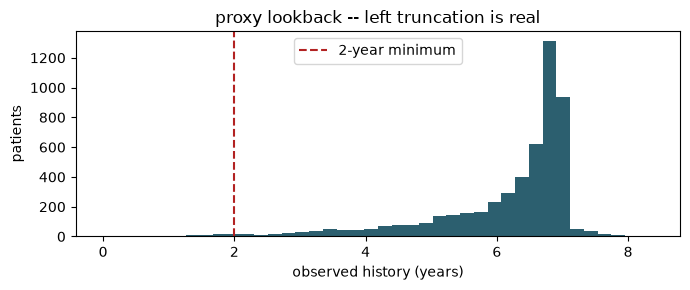


81 patients (1.5%) have under 2 years of history.
Exclude them from any analysis that depends on the ABSENCE of a code.


In [7]:
win = eo.observation_window(events)
print(win.lookback_days.describe().round(0).to_string())

plt.figure(figsize=(7, 3))
plt.hist(win.lookback_days / 365.25, bins=40, color='#2C5F6F')
plt.axvline(2, ls='--', c='firebrick', label='2-year minimum')
plt.xlabel('observed history (years)'); plt.ylabel('patients')
plt.title('proxy lookback -- left truncation is real'); plt.legend()
plt.tight_layout(); plt.show()

SHORT = win.loc[win.lookback_days < 730, 'person_id']
print(f"\n{len(SHORT)} patients ({len(SHORT)/len(win):.1%}) have under 2 years of history.")
print("Exclude them from any analysis that depends on the ABSENCE of a code.")

## 2 · Concept sets, resolved by name

**Goal:** show how a clinical concept like "letrozole" turns into an actual, checkable list of medical codes — and why we resolve it by *name* instead of hand-typing code numbers.

`CODESETS` in `ethos_omop.py` maps a clinical label to name patterns plus vocabularies.
Resolving by name rather than hardcoding concept_ids means the same notebook runs against
real Snowflake concepts and the demo extract alike.

*In plain terms: instead of writing down a fixed list of magic numbers ("code 19022830 means letrozole"), we write down a search pattern ("anything whose name matches 'letrozole' in the RxNorm vocabulary") and let the computer look up the matching codes every time. That way the same notebook keeps working even if the underlying code numbers differ between data sources.*

**Always eyeball the resolution before trusting it.** This is the step where a bad regex
quietly poisons everything downstream.

In [8]:
# Eyeball it: what did the "letrozole" pattern actually match? Read
# straight from codesets.yaml (via eo.CODESETS) instead of retyping the
# patterns here, so this can't silently drift from what build_codesets()
# actually resolves.
lz_spec = eo.CODESETS['letrozole']
eo.resolve(concept, lz_spec['patterns'], vocabularies=lz_spec.get('vocabularies'))

,concept_id,concept_name,vocabulary_id,concept_code,domain_id
7978,19022830,letrozole 2.5 MG Oral Tablet,RxNorm,200064,Drug
894,1315947,letrozole 2.5 MG Oral Tablet [Femara],RxNorm,153124,Drug


In [9]:
# Medical coding systems are hierarchical: a drug "ingredient" (letrozole)
# can have several branded/dosed "products" under it, and a diagnosis can
# have several more specific children. `concept_ancestor` lets us walk that
# hierarchy in either direction.

# On real data, roll a drug ingredient DOWN to all its products via concept_ancestor.
lz = codesets['letrozole']
print("letrozole concepts, direct:      ", len(lz))
print("letrozole concepts, + descendants:", len(eo.expand_descendants(lz)))

# And roll an unspecified diagnosis UP to its parents -- e.g. `breast_cancer`,
# the comorbidity marker that distinguishes this cohort's oncology-indication
# subgroup (letrozole is the anchor here, not breast_cancer -- see Table 1).
bc = codesets['breast_cancer']
print("breast cancer parents, 1 level up:  ", len(eo.roll_up(bc, levels=1)))

letrozole concepts, direct:       2
letrozole concepts, + descendants: 2
breast cancer parents, 1 level up:   1


In [10]:
# `tag` collapses many concept_ids into one readable clinical label.
# Untagged events fall back to a slug of concept_name so sequences stay legible.
print(events.tag.value_counts().head(15).to_string())
print(f"\ntagged into a codeset: {events.in_codeset.mean():.1%}")

tag
venipuncture_for_blo__procedure__4102442         39904
letrozole_25_mg_oral__clinical_drug__19022830    19760
progesterone_measure__procedure__4263754         17686
estradiol_total__cpt4__2212320                   16366
therapeutic_procedur__cpt4__2314284              16126
psychotherapy_60_min__cpt4__43527905             15715
gonadotropin_chorion__cpt4__2212631              14214
manual_therapy_techn__cpt4__2314290              13609
female_infertility__disorder__201909             13591
low_back_pain__clinical_finding__194133          12978
transvaginal_echogra__procedure__4027510         12128
generalized_anxiety___disorder__434613           11785
chiropractic_manipul__cpt4__2314331              11573
complete_blood_count__procedure__4319466         10829
thyroid_stimulating___procedure__4246879         10724

tagged into a codeset: 8.9%


Roughly a quarter to a third of events land in a curated codeset. That ratio is normal and
it is a useful number to report: it quantifies how much of the record your hand-built
domain knowledge actually covers. Zack's unknown-unknowns objection is exactly the other
two thirds.

*In plain terms: we only defined clinical labels (letrozole, mastectomy, breast_cancer, ...) for the codes relevant to this specific question. Everything else in a patient's record still exists in the data, we just haven't given it a friendly name -- it isn't lost, and it's part of what later, more automated methods (Day 4's embeddings) can pick up on that our hand-picked labels can't.*

## 3 · The bag of codes, and the exact failure

**Goal for this section:** build the simplest possible patient representation — a checklist of which codes each patient has — and then show exactly where it breaks.

In [11]:
# The bag of codes, as AGE_SEX_CROSS says: 'plain' = one column per code | 'crossed' = ONLY crossed features, every code x the patient's sex x age band
# at the date of the event ('clomiphene_F_25-34'; a code that happens in two bands is two columns) | 'both' = the two together | 'extended' = the plain bag here (the sex and age band columns are added in section 4).
_vc   = events['tag'].value_counts()
codes = list(_vc[_vc >= 20].index)                         # min_count=20 events: the coarse first cut, as in bag_of_codes_sparse
if PLAIN:
    Xp, pids_p, cols_p = eo.bag_of_codes_sparse(events, min_count=20)     # sparse straight away: no dense patient x code table is ever built
    print("plain bag of codes:", Xp.shape, f"density {Xp.nnz / (Xp.shape[0] * Xp.shape[1]):.3%}")
else:
    Xp, cols_p, pids_p = None, [], np.sort(events['person_id'].unique())
if CROSS:
    Xc, cols_c = eo.age_sex_block(events, person, pids_p, codes, AGE_EDGES, min_patients=1, col='tag')     # one pass over the events
    print("crossed bag (code x sex x age band at the event):", Xc.shape, f"density {Xc.nnz / (Xc.shape[0] * Xc.shape[1]):.3%}")
else:
    Xc, cols_c = None, []

_X, _cols = (Xp, cols_p) if PLAIN else (Xc, cols_c)
display(pd.DataFrame(_X[:5, :10].toarray(), index=pids_p[:5], columns=_cols[:10]))
_i = 0      # the first patient: the columns that are on
if PLAIN:
    print(f"\npatient {pids_p[_i]}  plain  :", [cols_p[j] for j in Xp[_i].indices][:8])
if CROSS:
    print(f"patient {pids_p[_i]}  crossed:", [cols_c[j] for j in Xc[_i].indices][:8])

plain bag of codes: (5238, 4223) density 2.284%


crossed bag (code x sex x age band at the event): (5238, 16303) density 0.625%


,025_mg_05_mg_dose_15__branded_drug__793152,025_mg_05_mg_dose_3___branded_drug__741834,02_ml_sarscov2_covid__quant_branded_drug__37355138,036_ml_follitropin_b__quant_branded_drug__43011837,03_ml_enoxaparin_sod__quant_clinical_drug__40160970,03_ml_sarscov2_covid__quant_branded_drug__1735839,03_ml_sarscov2_covid__quant_branded_drug__37355134,03_ml_sarscov2_covid__quant_branded_drug__747830,03_ml_sarscov2_covid__quant_branded_drug__747832,03_ml_sarscov2_covid__quant_clinical_drug__747831
1949,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4358,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4531,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5216,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5294,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



patient 1949  plain  : ['05_ml_bordetella_per__quant_branded_drug__42800267', '05_ml_hepatitis_b_su__quant_branded_drug__35201909', '05_ml_influenza_a_vi__quant_branded_drug__37355093', '20_nirmatrelvir_150___branded_pack__702578', '21_ethinyl_estradiol__branded_pack__1510765', '21_ethinyl_estradiol__branded_pack__44818390', '21_methylprednisolon__clinical_pack__19129398', '3_ml_insulin_detemir__quant_branded_drug__1516981']
patient 1949  crossed: ['05_ml_bordetella_per__quant_branded_drug__42800267_F_35-44', '05_ml_hepatitis_b_su__quant_branded_drug__35201909_F_35-44', '05_ml_influenza_a_vi__quant_branded_drug__37355093_F_35-44', '20_nirmatrelvir_150___branded_pack__702578_F_35-44', '21_ethinyl_estradiol__branded_pack__1510765_F_35-44', '21_ethinyl_estradiol__branded_pack__44818390_F_35-44', '21_methylprednisolon__clinical_pack__19129398_F_35-44', '3_ml_insulin_detemir__quant_branded_drug__1516981_F_35-44']


**Goal:** get a feel for `X` before we do anything clever with it — which codes are common, which are rare, and how that's different from what an NMF component (two sections down) will tell us.

Prevalence read directly off `X`, before any factorization -- contrasted with the NMF-loading readout two sections down. A loading tells you what's characteristic of a *component*, not how common a code is overall: `letrozole` is 100% prevalent here yet won't dominate any single NMF component once it's dropped as near-constant.

*In plain terms: "prevalence" here just means "what % of patients have this code at all." That's a different question from "which codes define this cluster/component" -- a code can be common across the whole cohort (like `letrozole`, since that's how the cohort was defined) without being distinctive of any particular subgroup.*

`AGE_SEX_CROSS` decides what the bag holds. `'plain'`: one column per code. `'crossed'`: **only crossed columns**, every code crossed with the patient's **sex and age band at the date of the event** (`clomiphene_F_25-34`, `pregnancy_test_F_25-34`); a patient who had the code in two age bands has two columns. `'both'`: the plain and the crossed columns together. `'extended'`: the plain columns plus the patient's sex and age band at **each letrozole exposure** (a patient exposed to letrozole at 38 and again at 44 has both `demo_age_35-44` and `demo_age_45-54`; sex is one column per patient), one-hot, not crossed with any code (section 4). With `'crossed'` the plain code is not a column: it is kept as a reference for names and prevalence (`Xs_tok`, below).

plain: 4223 columns, prevalence range 0.019% - 99.847%


,prevalence
letrozole_25_mg_oral__clinical_drug__19022830,99.8%
venipuncture_for_blo__procedure__4102442,63.6%
thyroid_stimulating___procedure__4246879,48.9%
complete_blood_count__procedure__4319466,47.9%
gynecologic_examinat__procedure__4306780,42.9%
comprehensive_metabo__procedure__3661905,42.8%
hemoglobin_a1c_measu__procedure__4184637,41.5%
gonadotropin_chorion__cpt4__2212631,40.5%
transvaginal_echogra__procedure__4027510,40.3%
urine_pregnancy_test__procedure__4014769,40.0%


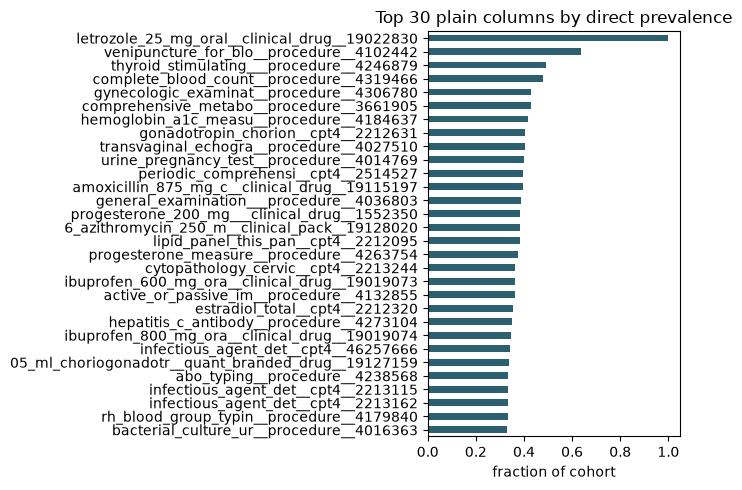

crossed (code x sex x age band at the event): 16303 columns, prevalence range 0.019% - 51.680%


,prevalence
letrozole_25_mg_oral__clinical_drug__19022830_F_25-34,51.7%
letrozole_25_mg_oral__clinical_drug__19022830_F_35-44,45.3%
venipuncture_for_blo__procedure__4102442_F_25-34,36.0%
venipuncture_for_blo__procedure__4102442_F_35-44,34.3%
thyroid_stimulating___procedure__4246879_F_25-34,26.5%
periodic_comprehensi__cpt4__2514527_F_25-34,25.6%
thyroid_stimulating___procedure__4246879_F_35-44,25.4%
complete_blood_count__procedure__4319466_F_25-34,24.9%
complete_blood_count__procedure__4319466_F_35-44,24.5%
gynecologic_examinat__procedure__4306780_F_25-34,24.4%


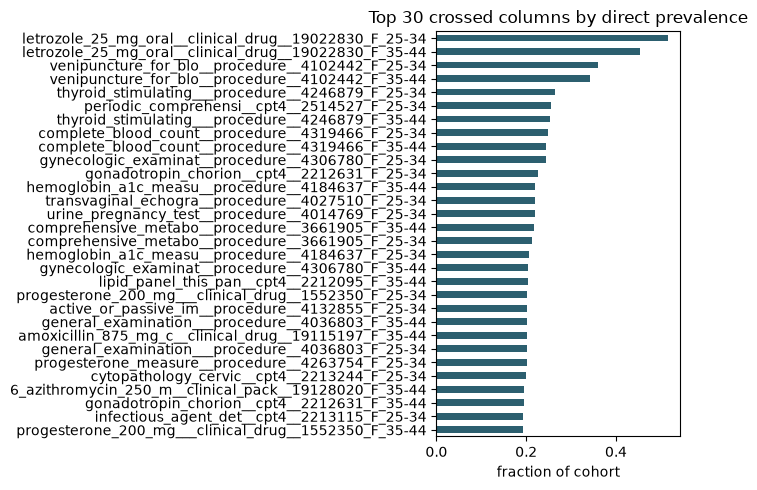

crossed copies of venipuncture_for_blo__procedure__4102442:


,prevalence
venipuncture_for_blo__procedure__4102442_F_25-34,36.0%
venipuncture_for_blo__procedure__4102442_F_35-44,34.3%
venipuncture_for_blo__procedure__4102442_F_45-54,3.3%
venipuncture_for_blo__procedure__4102442_F_<25,3.0%
venipuncture_for_blo__procedure__4102442_F_55-64,0.8%
venipuncture_for_blo__procedure__4102442_F_65+,0.0%


In [12]:
for name, X, cols in [('plain', Xp, cols_p), ('crossed (code x sex x age band at the event)', Xc, cols_c)]:
    if X is None:
        continue
    prevalence = pd.Series(np.asarray(X.mean(axis=0)).ravel(), index=cols).sort_values(ascending=False)
    print(f"{name}: {len(prevalence)} columns, prevalence range "
          f"{prevalence.min():.3%} - {prevalence.max():.3%}")
    display(prevalence.head(30).to_frame('prevalence').style.format('{:.1%}'))

    plt.figure(figsize=(7, 5))
    prevalence.head(30).iloc[::-1].plot.barh(color='#2C5F6F')
    plt.xlabel('fraction of cohort'); plt.title(f'Top 30 {name.split(" ")[0]} columns by direct prevalence')
    plt.tight_layout(); plt.show()

if CROSS:       # the crossed copies of the commonest code that is not a curated group
    _t = next(t for t in events['tag'].value_counts().index if t not in codesets and t != ANCHOR)
    print(f"crossed copies of {_t}:")
    display(prevalence[[c for c in prevalence.index if c.rsplit('_', 2)[0] == _t]].to_frame('prevalence').style.format('{:.1%}'))

### Choosing `min_count` from prevalence

`bag_of_codes(min_count=...)` drops a code unless it has at least that many **events** in the
whole cohort, so one patient with 20 refills can keep a code alive. What actually limits a
model is how many **patients** carry a code, so this cell works in patients.

*In plain terms: a code seen in only a handful of patients can't form a reliable pattern, but
dropping too many codes throws away real signal. This table shows, for each cutoff, how many
columns survive and how much of the patient-by-code information is kept, then suggests a
cutoff.*

The suggested floor is the number of patients a code needs so that a training split is
expected to contain at least `MIN_TRAIN_PATIENTS` of them: `ceil(MIN_TRAIN_PATIENTS * cohort /
N_TRAIN)`. It scales with cohort size. It is a heuristic, not a statistical test, and it works
on `events`, so it does not need the full matrix (which would be too large to build with no
cutoff).

With `AGE_SEX_CROSS = 'crossed'` or `'both'` the table also counts the crossed bag of section 3 (every code x sex x age band at the event): `crossed columns` and `crossed pairs_kept_%` for the same cutoffs, and the sum with the plain columns. The floor itself does not depend on the number of columns: it is per column, so the same number of patients applies to a crossed column. Section 3 crosses only the codes with at least 20 events, so the crossed counts of the rows below 20 patients are incomplete.

The floor is applied **once**, to the columns of the bag that `AGE_SEX_CROSS` picked. A crossed column needs `MIN_PATIENTS` patients, so a code split over many age bands and sexes needs enough patients in each. The plain codes above the floor are always built, as the reference (names, prevalence). The next cell builds them and the crossed columns above the floor, and section 4 makes the single matrix `Xs` that every later cell (distances, NMF) uses.


,prevalence_%,columns,pairs_kept_%,crossed columns,crossed pairs_kept_%,plain + crossed columns
rule,,,,,,
>= 1 patients,0.0191,11001,100.00,16303.0,100.00,27304.0
>= 2 patients,0.0382,7869,99.40,13165.0,99.41,21034.0
>= 5 patients,0.0955,5250,98.04,9205.0,97.37,14455.0
>= 10 patients,0.1909,3786,96.20,6341.0,93.76,10127.0
>= 20 patients,0.3818,2695,93.34,4015.0,87.86,6710.0
>= 35 patients,0.6682,1980,89.85,2780.0,81.91,4760.0
>= 50 patients,0.9546,1619,87.02,2106.0,76.69,3725.0
>= 100 patients,1.9091,1069,79.62,1176.0,64.53,2245.0
>= 200 patients,3.8183,601,67.06,562.0,48.36,1163.0


crossed columns come from the codes with >= 20 events (section 3), so the rows below 20 patients undercount them; from 20 patients up the rows are complete
cohort 5238 patients, training split 3142
suggested floor: 9 patients (0.172% prevalence) -> 3979 of 11001 columns, 96.5% of patient-code pairs kept
codeset tags below the floor: none
crossed columns kept at the same floor (9 patients): 6,800 of 16,303
crossed pairs kept: 94.5% of the (patient, code, sex, band) pairs
AGE_SEX_CROSS = 'both': matrix to fit 10,779 columns


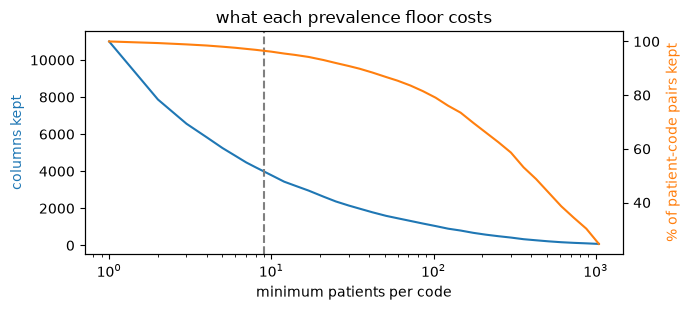


To apply it, build the matrix from the kept codes only (min_count=1 on pre-filtered events):
    Xsp, person_ids, all_cols = eo.bag_of_codes_sparse(events[events.tag.isin(KEEP_TAGS)], min_count=1)


In [13]:
import math

MIN_TRAIN_PATIENTS = 5            # a code should appear in >= this many patients of a training split
n_pat   = events.person_id.nunique()
N_TRAIN = min(20_000, int(0.6 * n_pat))      # training-split size used by the k-sweep cells

# patients per code, and events per code (what bag_of_codes' min_count counts)
code, tags = pd.factorize(events['tag'])
key        = events['person_id'].to_numpy(np.int64) * len(tags) + code
prev_pat   = pd.Series(np.bincount(np.unique(key) % len(tags), minlength=len(tags)), index=tags)
ev_cnt     = pd.Series(np.bincount(code, minlength=len(tags)), index=tags)
all_pairs  = int(prev_pat.sum())             # distinct (patient, code) pairs = ones in the full 0/1 matrix

def summarize(mask):
    return {'columns': int(mask.sum()),
            'pairs_kept_%': round(100 * prev_pat[mask].sum() / all_pairs, 2)}

CUTOFFS = [1, 2, 5, 10, 20, 35, 50, 100, 200, 500]
rows = [{'rule': f'>= {p} patients', 'prevalence_%': round(100 * p / n_pat, 4), **summarize(prev_pat >= p)}
        for p in CUTOFFS]
rows.append({'rule': 'current min_count=20 (events)', 'prevalence_%': np.nan, **summarize(ev_cnt >= 20)})
rule_tbl = pd.DataFrame(rows).set_index('rule')

if CROSS:       # the same rules on the crossed bag of section 3 (Xc is binary: a column sum is a number of patients)
    pc      = np.asarray(Xc.sum(axis=0)).ravel()
    pairs_c = int(pc.sum())                  # distinct (patient, code, sex, band) cells = ones in the full crossed matrix
    cross   = pd.DataFrame([{'rule': f'>= {p} patients', 'crossed columns': int((pc >= p).sum()),
                             'crossed pairs_kept_%': round(100 * pc[pc >= p].sum() / pairs_c, 2)} for p in CUTOFFS]).set_index('rule')
    rule_tbl = rule_tbl.join(cross)
    rule_tbl['plain + crossed columns'] = rule_tbl['columns'] + rule_tbl['crossed columns']

MIN_PATIENTS = math.ceil(MIN_TRAIN_PATIENTS * n_pat / N_TRAIN)
KEEP_TAGS    = prev_pat.index[prev_pat >= MIN_PATIENTS]
display(rule_tbl)
if CROSS:
    print("crossed columns come from the codes with >= 20 events (section 3), so the rows below 20 patients undercount them; from 20 patients up the rows are complete")

# the clinical (codeset) tags are the ones the analysis is about -- do any fall below the floor?
codeset_tags = [t for t in codesets if t in prev_pat.index]
lost = prev_pat[codeset_tags][lambda s: s < MIN_PATIENTS]
print(f"cohort {n_pat} patients, training split {N_TRAIN}")
print(f"suggested floor: {MIN_PATIENTS} patients ({100 * MIN_PATIENTS / n_pat:.3f}% prevalence) -> "
      f"{len(KEEP_TAGS)} of {len(prev_pat)} columns, "
      f"{100 * prev_pat[KEEP_TAGS].sum() / all_pairs:.1f}% of patient-code pairs kept")
print("codeset tags below the floor:", lost.to_dict() if len(lost) else "none")
if CROSS:       # what the same floor leaves of the crossed bag
    _tk = np.array([nm.rsplit('_', 2)[0] for nm in cols_c])
    _kc = (pc >= MIN_PATIENTS) & (_tk != ANCHOR)
    print(f"crossed columns kept at the same floor ({MIN_PATIENTS} patients): {int(_kc.sum()):,} of {len(cols_c):,}")
    print(f"crossed pairs kept: {100 * pc[_kc].sum() / pairs_c:.1f}% of the (patient, code, sex, band) pairs")
n_fit = (len(KEEP_TAGS.difference([ANCHOR])) if PLAIN else 0) + (int(_kc.sum()) if CROSS else 0)
print(f"AGE_SEX_CROSS = '{AGE_SEX_CROSS}': matrix to fit {n_fit:,} columns{' + the sex and age band columns of section 4' if DEMO else ''}")

fig, ax = plt.subplots(figsize=(7, 3.2))
ps = np.unique(np.round(np.geomspace(1, max(2, prev_pat.max() / 5), 40)).astype(int))
ax.plot(ps, [(prev_pat >= p).sum() for p in ps], color='C0')
ax.set_xscale('log'); ax.set_xlabel('minimum patients per code'); ax.set_ylabel('columns kept', color='C0')
ax2 = ax.twinx()
ax2.plot(ps, [100 * prev_pat[prev_pat >= p].sum() / all_pairs for p in ps], color='C1')
ax2.set_ylabel('% of patient-code pairs kept', color='C1')
ax.axvline(MIN_PATIENTS, ls='--', c='grey')
ax.set_title('what each prevalence floor costs')
plt.tight_layout(); plt.show()

print("\nTo apply it, build the matrix from the kept codes only (min_count=1 on pre-filtered events):")
print("    Xsp, person_ids, all_cols = eo.bag_of_codes_sparse(events[events.tag.isin(KEEP_TAGS)], min_count=1)")

In [14]:
Xsp, person_ids, all_cols = eo.bag_of_codes_sparse(events[events.tag.isin(KEEP_TAGS)], min_count=1)   # the plain codes above the floor (fitted for 'plain' and 'both', a reference for 'crossed')
print("plain codes above the floor:", Xsp.shape)

if CROSS:       # the same floor on the crossed bag of section 3: a crossed column needs >= MIN_PATIENTS patients, and its code must be above the floor too
    assert np.array_equal(pids_p, person_ids), 'the crossed bag and the plain matrix must have the same patients in the same order'
    _n    = np.asarray(Xc.sum(axis=0)).ravel()
    _tok  = set(all_cols)
    _keep = [j for j, nm in enumerate(cols_c) if _n[j] >= MIN_PATIENTS and nm.rsplit('_', 2)[0] in _tok]
    Xc_kept, cols_c_kept = Xc[:, _keep].tocsr(), [cols_c[j] for j in _keep]
    print(f"crossed features above the floor: {Xc_kept.shape}  ({len(_keep):,} of the {len(cols_c):,} crossed columns, >= {MIN_PATIENTS} patients each)")
else:
    Xc_kept, cols_c_kept = None, []

plain codes above the floor: (5238, 3979)
crossed features above the floor: (5238, 6800)  (6,800 of the 16,303 crossed columns, >= 9 patients each)


In [15]:
# Two letrozole + breast_cancer patients with the same group-level checklist and opposite probe labels (fertility vs oncology).
weak = eo.weak_labels(events)                       # rule-based probe labels: fertility vs oncology
lab  = weak.set_index('person_id').weak_label

_eg = events[events.groups.notna()]
Xg = eo.bag_of_codes(_eg.assign(group=_eg.groups.astype(str).str.split('|')).explode('group').reset_index(drop=True), col='group', min_count=1)   # group-level checklist (a concept counts in EVERY group it is in), demo only
both = [p for p in person_ids
        if Xg.loc[p].get('letrozole', 0) == 1
        and Xg.loc[p].get('breast_cancer', 0) == 1
        and p in lab.index]

a = next((p for p in both if lab[p] == 'fertility'), None)
b = next((p for p in both if lab[p] == 'oncology'),  None)
assert a and b, ("No matching-bag pair found in this sample. Widen the `both` filter, "
                 "or inspect `both` to see which side is missing.")

print("bag-of-codes view -- indistinguishable on letrozole + breast_cancer alone:")
display(Xg.loc[[a, b], ['letrozole', 'breast_cancer']])

print("\nactual timelines -- obviously different:")
# FOCUS = eo.FERTILITY_TAGS / eo.ONCOLOGY_TAGS -- the constants weak_labels() used to build `lab` -- plus the exposure / anchor tags
FOCUS = ['letrozole', 'breast_cancer'] + eo.FERTILITY_TAGS + eo.ONCOLOGY_TAGS
for pid in (a, b):
    s = events[(events.person_id == pid) & eo.group_mask(events, FOCUS)]
    print(f"\n  person_id {pid}  ({lab[pid]})")
    print(s[['event_date', 'groups', 'tag']].drop_duplicates('tag').to_string(index=False))

letrozole patients: 5238   labelled: 3835   both-evidence (dropped): 484   no-evidence (dropped): 919


bag-of-codes view -- indistinguishable on letrozole + breast_cancer alone:


group,letrozole,breast_cancer
person_id,,
4460222,1,1
308016,1,1



actual timelines -- obviously different:

  person_id 4460222  (fertility)
event_date         groups                                           tag
2021-04-22 pregnancy_test      urine_pregnancy_test__procedure__4014769
2025-06-21      letrozole letrozole_25_mg_oral__clinical_drug__19022830
2026-07-24  breast_cancer       primary_malignant_ne__disorder__4162253

  person_id 308016  (oncology)
event_date               groups                                           tag
2022-02-08       receptor_assay           immunohistochemistry__cpt4__2213300
2022-02-08       receptor_assay          immunohistochemistry__cpt4__46257426
2022-04-21       receptor_assay           special_stain_includ__cpt4__2213288
2023-06-08        breast_cancer       primary_malignant_ne__disorder__4162253
2023-06-08 lymph_node_procedure           injection_procedure___cpt4__2108492
2023-06-08           mastectomy         simple_mastectomy__procedure__4066543
2023-06-08 lymph_node_procedure          intraoperative_id

**That is the motivation for the whole week.** Identical features, opposite risk. The
information lives in the order, and the representation threw it away.

This is not a modelling failure. No estimator can recover something the input does not
contain.

*In plain terms: this isn't a case of "use a fancier algorithm and it'll figure it out." The bag-of-codes table literally does not contain the information needed to tell these two patients apart -- both rows are 1, 1. No amount of machine learning can pull a distinction out of data where the distinction was never recorded in the first place. You have to fix the representation, not the model.*

### On `weak_labels()`

**Goal:** since there's no ground-truth "this patient took letrozole for fertility / for cancer" label in claims data, build a trustworthy *stand-in* label we can use to check our work — and be upfront about how it's built and where it can go wrong.

There are no adjudicated labels in claims data. `weak_labels()` builds probe labels for the
letrozole indication from **corroborating co-evidence only** — clomiphene, gonadotropins and
infertility diagnoses on one side; mastectomy, biopsy, tamoxifen and anastrozole on the
other. Patients with both kinds of evidence, or neither, are dropped, and the counts are
printed so you can see how many.

*In plain terms: instead of guessing the reason for letrozole directly, we look for other, more specific evidence nearby — did the patient also have a fertility drug or an infertility diagnosis? Did they also have a mastectomy or a cancer drug? If the evidence points clearly one way, we use that as the label. If it points both ways, or neither way, we honestly say "we don't know" and drop them rather than force a guess.*

**The time delta is deliberately not used.** If you label by "drug before diagnosis" and
then test whether the time delta predicts the label, you get perfect accuracy by
construction and have learned nothing. These labels are for evaluation, never features.

*In plain terms: it would be tempting to say "letrozole came before the cancer diagnosis, so it must be fertility-related." But that's using the very thing we're trying to test (timing) to build the answer key -- then "discovering" that timing predicts the answer would be circular, not a real finding. So the answer key is built from a different, independent kind of evidence, and timing is only used afterward to see if it can predict that answer.*

## 4 · Distance metrics disagree

**Goal:** show that "how similar are two patients" isn't one universal number — the metric you pick changes the answer, and picking the wrong one for claims data quietly breaks everything downstream.

In [16]:
from sklearn.metrics import pairwise_distances
import scipy.sparse as sp

# letrozole is the cohort anchor -- 100% prevalence here, so it's a near-
# constant column that carries no discriminative signal and would just eat a
# component. Drop it before any distance/NMF fit; X itself (with the
# column) stays untouched for the two-patient demo above and Table 1 below.
# Everything downstream works on a SPARSE copy (Xs): same values as the dense matrix without the
# anchor column, a fraction of the memory, and faster NMF fits. No dense copy without
# `letrozole` is ever built.
# ONE matrix from here on, as AGE_SEX_CROSS says: 'plain' = the plain codes above the floor | 'crossed' = only the crossed features above the floor | 'both' = the two | 'extended' = plain + the sex and age band one-hots. The anchor is out (its crossed copies too).
# The plain codes (TOK_COLS, Xs_tok) are always kept as the reference: names of bundles and prevalence.
_all     = pd.Index(all_cols)
_anchor  = set(events.loc[eo.group_mask(events, ANCHOR), 'tag'])
TOK_COLS = [c for c in _all if c not in _anchor]                  # the plain codes: what Letrozole_NMF_PrefixSpan_full fits on; the bundle tables name codes, not crossed columns
n_pat    = Xsp.shape[0]
Xs_tok   = Xsp[:, _all.get_indexer(TOK_COLS)].astype(float).tocsr()
anchor_events = events.loc[eo.group_mask(events, ANCHOR)]                                            # every letrozole exposure
first_anchor  = anchor_events.groupby('person_id')['event_date'].min().rename('ref_date').to_frame()
demo      = eo.demographics(person, first_anchor, AGE_EDGES)      # read-out only: sex and age band at the FIRST letrozole exposure, the stratum of Part A+
BLOCKS   = {}                                                     # block -> (matrix, column names), rows aligned with person_ids
if CROSS:
    _ok = [j for j, nm in enumerate(cols_c_kept) if nm.rsplit('_', 2)[0] not in _anchor]        # the anchor's own crossed copies go too
    BLOCKS['S'] = (Xc_kept[:, _ok].tocsr(), [cols_c_kept[j] for j in _ok])
BLOCKS['D'] = eo.demographic_block(anchor_events, person, person_ids, AGE_EDGES, min_patients=MIN_PATIENTS)    # the age band AT EACH letrozole exposure (and a sex column when the cohort has more than one sex), one-hot; always built (a few columns), fitted only in 'extended'
_Xd, _nd = BLOCKS['D']        # a column that every patient has carries no information: drop the sex column of a one-sex cohort (this one: all women)
_const = [j for j, n in enumerate(_nd) if n.startswith('demo_sex_') and _Xd[:, j].nnz == _Xd.shape[0]]
if _const:
    print('constant columns dropped from the demographic block (every patient has them):', [_nd[j] for j in _const])
    _kd = [j for j in range(len(_nd)) if j not in _const]
    BLOCKS['D'] = (_Xd[:, _kd].tocsr(), [_nd[j] for j in _kd])
WEIGHT   = {'S': W_S, 'D': W_D}
assert not ({n for _, names in BLOCKS.values() for n in names} & set(TOK_COLS)), 'a crossed column has the name of a plain column'

def assemble(blocks, plain=True):
    """Plain codes (when plain=True) + the named blocks -> (CSR matrix, column names)."""
    mats  = ([Xs_tok] if plain else []) + [WEIGHT[b] * BLOCKS[b][0] for b in blocks]
    names = (TOK_COLS if plain else []) + [n for b in blocks for n in BLOCKS[b][1]]
    return sp.hstack(mats, format='csr'), names

FIT = [b for b, on in (('S', CROSS), ('D', DEMO)) if on]       # the blocks AGE_SEX_CROSS puts in the fitted matrix; the others are built but not fitted
Xs, nmf_cols = assemble(FIT, plain=PLAIN)      # the matrix the distances and the NMF use
print(f"Xs {Xs.shape}: '{AGE_SEX_CROSS}' bag, density {Xs.nnz / (Xs.shape[0] * Xs.shape[1]):.3%}   (plain codes above the floor, the reference: {Xs_tok.shape[1]:,})")

def code_H(components):
    """NMF components (k x len(nmf_cols)) -> k x codes: the loadings of a code's plain column and of its crossed columns (sex, band) are summed, so tables can name codes. The sex and age band columns of 'extended' are not codes: they drop out here (Part A+ reads them)."""
    H = pd.DataFrame(components, columns=nmf_cols)
    tok = set(TOK_COLS)
    H = H.T.groupby(pd.Series([n if n in tok else n.rsplit('_', 2)[0] for n in nmf_cols], index=nmf_cols)).sum().T
    return H[[c for c in TOK_COLS if c in H.columns]]

def dist_to_all(row, M, metric, chunk=1_000):   # 10,000 dense rows would not fit once the crossed columns are in
    """Distances from one row to every row of sparse M, densifying only `chunk` rows at a time."""
    return np.concatenate([pairwise_distances(row, M[i:i + chunk].toarray(), metric=metric)[0]
                           for i in range(0, M.shape[0], chunk)])

sub = Xs[:400].toarray()
for m in [#'euclidean', 
          'cosine', 'jaccard']:
    D  = pairwise_distances(sub, metric=m)
    iu = np.triu_indices(len(sub), 1)
    print(f"{m:10s} mean={D[iu].mean():.3f}  sd={D[iu].std():.3f}")

pos = list(person_ids).index(a)
print()
for m in [#'euclidean', 
          'cosine', 'jaccard']:
    D  = dist_to_all(Xs[pos:pos+1].toarray(), Xs, m)
    nn = [person_ids[i] for i in np.argsort(D)[1:6]]
    print(f"{m:10s} neighbours of {a}: {[lab.get(p, '?') for p in nn]}")

constant columns dropped from the demographic block (every patient has them): ['demo_sex_F']
Xs (5238, 10769): 'both' bag, density 1.773%   (plain codes above the floor, the reference: 3,977)
cosine     mean=0.902  sd=0.065


/opt/miniconda3/envs/ethos_llm/lib/python3.13/site-packages/sklearn/metrics/pairwise.py:2480: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


jaccard    mean=0.952  sd=0.036

cosine     neighbours of 4460222: ['?', 'fertility', 'fertility', '?', 'fertility']


jaccard    neighbours of 4460222: ['?', 'fertility', '?', 'fertility', 'fertility']


/opt/miniconda3/envs/ethos_llm/lib/python3.13/site-packages/sklearn/metrics/pairwise.py:2480: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)
/opt/miniconda3/envs/ethos_llm/lib/python3.13/site-packages/sklearn/metrics/pairwise.py:2480: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)
/opt/miniconda3/envs/ethos_llm/lib/python3.13/site-packages/sklearn/metrics/pairwise.py:2480: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)
/opt/miniconda3/envs/ethos_llm/lib/python3.13/site-packages/sklearn/metrics/pairwise.py:2480: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)
/opt/miniconda3/envs/ethos_llm/lib/python3.13/site-packages/sklearn/metrics/pairwise.py:2480: DataConversionWarning: Data was converted to boolean for metric ja

**Rule of thumb for claims: use cosine on binary or count code vectors.** Euclidean punishes
patients simply for having long histories, so the distance ends up driven by utilisation
volume rather than clinical content — which in your data is partly a function of what got
ordered during underwriting.

*In plain terms: a patient with 200 recorded codes isn't automatically "less similar" to everyone else than a patient with 20 codes — but a naive distance metric (Euclidean) treats it that way, because it's sensitive to how many codes are turned on, not just which ones. Cosine distance cares about the pattern of codes, not the raw count, which is what we actually want to compare.*

## 5 · The curse of dimensionality

On the full Ethos vocabulary you will have tens of thousands of columns, not the few dozen
here. At that width every pair of patients becomes equidistant and "nearest neighbour" stops
meaning anything.

*In plain terms: with only a handful of columns, "similar" and "different" are easy to tell apart. Once you have tens of thousands of columns and each patient only has a handful of them turned on, almost every pair of patients ends up looking roughly equally (dis)similar to each other -- there's no longer a meaningful "close" versus "far." This is a general math fact (the "curse of dimensionality"), not something specific to our data.*

In [17]:
rng = np.random.default_rng(0)
print(f"{'dims':>6} {'min/max distance ratio':>24}")
for d in [10, 50, 200, 1000, 5000]:
    Zr = (rng.random((200, d)) < 0.02).astype(float)     # sparse, like code data
    D  = pairwise_distances(Zr)
    iu = np.triu_indices(200, 1)
    print(f"{d:>6} {D[iu].min() / D[iu].max():>24.3f}")
print("\nRatio -> 1 means every patient is equally far from every other.")

  dims   min/max distance ratio
    10                    0.000
    50                    0.000
   200                    0.000
  1000                    0.568
  5000                    0.782

Ratio -> 1 means every patient is equally far from every other.


## 5b · Age and sex at exposure: what is in the matrix

`AGE_SEX_CROSS` picked what the bag of codes holds, and `Xs` is what is left after the prevalence floor (applied once, above): `'plain'` the plain codes, `'crossed'` only the crossed features, `'both'` the two together, `'extended'` the plain codes plus the sex and age band one-hots (D). A crossed feature is a code (a curated group or a concept-level code) copied into the sex and age band of the patient **at the date of each event**: `clomiphene_F_25-34`, `pregnancy_test_F_25-34`. Age is `(event date - birth date) / 365.25`, cut into 10-year bands (`<25`, `25-34`, `35-44`, `45-54`, `55-64`, `65+`; `AGE_EDGES` sets them); sex is the person's own. A patient with clomiphene at 28 and again at 38 has both `clomiphene_F_25-34` and `clomiphene_F_35-44`.

Sex does not change, and every patient of this cohort is a woman, so here a crossed feature differs from its plain code by the age band only: expect components that are age-band versions of a care pattern, and read the NMI in Part A+ (`'both'` keeps the plain columns, which every age band shares). The plain codes are always a reference (`TOK_COLS`, `Xs_tok`): bundle tables, the components json and the group loadings fold the loadings back to codes (`code_H`: plain and crossed columns of a code summed). A crossed name splits back with `name.rsplit('_', 2)` into code, sex and band.

In the chest pain notebooks a sex and age one-hot block at full weight, together with recency windows, took over the components (two of them were just `sex=F` and `sex=M`); here the one-hot block is `'extended'` with a weight `W_D`, and recency is left out.

This section only reads the matrix. `demo` (sex and age band at the **first letrozole exposure**) is for reading the results, who is in each component. It is never a feature. The D features of `'extended'` come from the letrozole exposures themselves: the age band at **each** letrozole exposure, so a patient exposed to letrozole at 38 and again at 44 has `demo_age_35-44` and `demo_age_45-54`, plus one sex column (`demo_sex_F`, weight `W_D`).

*In plain terms: with `'crossed'` every kind of care is split by the sex and 10-year age band the patient was in when it happened, and the bundles are found on those split features, so a bundle can say "blood count at 35-44 in women".*

In [18]:
# `demo` (sex and age band at the first letrozole exposure) is built in section 4: a read-out only
LABEL = {'S': 'S code x sex x age band at the event', 'D': 'D age band at each letrozole exposure (one-hot)'}
rows = [{'block': 'plain codes' + (' (reference, not fitted)' if not PLAIN else ''), 'columns': Xs_tok.shape[1], 'non-zeros': Xs_tok.nnz, 'weight': 1.0}]
rows += [{'block': LABEL[b] + ('' if b in FIT else ' (built, not fitted)'), 'columns': M.shape[1], 'non-zeros': M.nnz, 'weight': WEIGHT[b]} for b, (M, _) in BLOCKS.items()]
display(pd.DataFrame(rows).set_index('block'))
print(f"matrix the NMF is fitted on: {Xs.shape}, density {Xs.nnz / (Xs.shape[0] * Xs.shape[1]):.3%}, about {(Xs.data.nbytes + Xs.indices.nbytes + Xs.indptr.nbytes) / 1e9:.1f} GB")

if 'S' in BLOCKS:       # how the S cells spread over sex and age band (patient x code x band): the size of the tails shows here
    _s = pd.DataFrame([n.rsplit('_', 2) for n in BLOCKS['S'][1]], columns=['code', 'sex', 'band'])
    _s['cells'] = np.asarray(BLOCKS['S'][0].sum(axis=0)).ravel()
    print("\nS cells (patient x code x band) by sex and age band at the event:")
    display(_s.pivot_table(index='band', columns='sex', values='cells', aggfunc='sum', fill_value=0).reindex(eo.age_band_labels(AGE_EDGES)).dropna(how='all'))

,columns,non-zeros,weight
block,,,
plain codes,3977,501103,1.0
S code x sex x age band at the event,6792,498886,1.0
"D age band at each letrozole exposure (one-hot) (built, not fitted)",6,5549,0.5


matrix the NMF is fitted on: (5238, 10769), density 1.773%, about 0.0 GB

S cells (patient x code x band) by sex and age band at the event:


sex,F
band,
<25,11069.0
25-34,229577.0
35-44,237751.0
45-54,16374.0
55-64,3256.0
65+,859.0


## 6 · NMF

**Goal:** compress thousands of sparse code columns into a handful of components per patient. NMF only allows non-negative parts, so each component reads as a set of co-occurring codes you can name.

*In plain terms: the wide, sparse `X` table (thousands of mostly-zero columns) is summarised into a few dozen themes, each a bundle of care that tends to happen together in the same patients.*

### NMF and Choosing k for the NMF

The k=12 above was chosen by reading the components. This sweep adds numbers for it, the
NMF counterpart of Day 2's elbow + bootstrap-ARI table for KMeans.

*In plain terms: fit the NMF at several values of k and, for each one, check how well it
explains patients it was never fit on, and whether the same bundles come back on re-draws. Then pick a k where adding
more components stops paying for itself but the bundles are still reproducible.*

Every k is fit on the same `N_SWEEP` training patients and scored on a disjoint `N_HELD`
held-out set, so the comparison is fair and the error is not just training fit.

The whole sweep is repeated on every split in `SPLIT_SEEDS` (independent random train / held-out
splits of the cohort), each with `N_BOOT_K` bootstrap refits per k. More refits only sharpen the
estimate within one split. Several splits show whether a k looks stable only because of the
patients it happened to see. Every NMF fit in this section uses the same settings (`NMF_KW`,
defined in the stability cell), so the base fit and its refits are converged the same way.

The fits run in parallel (`N_JOBS` workers, because sklearn's NMF uses one core per fit) on a
sparse copy of the matrix, `Xs`. The result is the same as the dense serial version; it is only
faster and much smaller in memory.

In [19]:
from sklearn.decomposition import NMF
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import adjusted_rand_score
import time

# one place for the NMF fit settings, used by every NMF fit in this section
NMF_KW = dict(init='nndsvd', random_state=0, max_iter=2000, tol=1e-4)

N_BOOT        = 3 if SMOKE else 10   # refits; each is a full NMF fit, raise once you know the runtime
N_BOOT_LOAD   = 3 if SMOKE else 200  # refits of the stability cell below, whose sex and age loadings Part A++ compares (~2 s each)
N_BOOT_SAMPLE = 20_000    # patients per resample (capped at the cohort size)
N_EVAL        = 20_000    # fixed patients used to compare argmax labels across refits

def _unit(M):
    return M / np.linalg.norm(M, axis=1, keepdims=True)

def nmf_stability(nmf_base, Xv, n_boot=N_BOOT, n_sample=N_BOOT_SAMPLE,
                  n_eval=N_EVAL, seed=0, pct_cols=None):
    """Bootstrap-refit NMF; return per-component matched cosine and per-boot ARI.

    Component order is arbitrary between fits (label switching), so each refit's
    components are matched to the base fit's by cosine similarity (Hungarian
    algorithm). ARI compares argmax patient partitions, which needs no matching.

    pct_cols (column indices) also returns, for every refit, the share (%) of each matched component's
    total loading that sits on those columns: an array (n_boot, k, len(pct_cols)), component j in the
    base fit's order. None when pct_cols is None.
    """
    k    = nmf_base.n_components_
    Hb   = _unit(nmf_base.components_)
    rng  = np.random.default_rng(seed)
    ev   = rng.choice(Xv.shape[0], min(n_eval, Xv.shape[0]), replace=False)
    lab0 = nmf_base.transform(Xv[ev]).argmax(1)
    cos, ari, pct = [], [], []
    for b in range(n_boot):
        t0  = time.perf_counter()
        idx = rng.choice(Xv.shape[0], min(n_sample, Xv.shape[0]), replace=True)
        m   = NMF(n_components=k, **NMF_KW).fit(Xv[idx])
        S        = Hb @ _unit(m.components_).T         # base x refit cosine
        rows, cols = linear_sum_assignment(-S)          # rows come back sorted 0..k-1
        cos.append(S[rows, cols])                       # cos[b][j] = base component j
        ari.append(adjusted_rand_score(lab0, m.transform(Xv[ev]).argmax(1)))
        if pct_cols is not None:
            Hm = m.components_[cols]                         # refit components in the base order
            pct.append((100 * Hm[:, pct_cols] / np.maximum(Hm.sum(axis=1, keepdims=True), 1e-12)).astype(np.float32))
        if (b + 1) % max(1, n_boot // 10) == 0:
            print(f"  boot {b + 1}/{n_boot}  {time.perf_counter() - t0:.0f}s  "
                  f"ARI {ari[-1]:.3f}")
    return np.array(cos), np.array(ari), (np.array(pct) if pct_cols is not None else None)

[Parallel(n_jobs=12)]: Using backend LokyBackend with 12 concurrent workers.


[Parallel(n_jobs=12)]: Done  50 out of  60 | elapsed:  4.1min remaining:   49.6s


60 jobs on 12 workers; summed fit time 48.8 CPU-min


[Parallel(n_jobs=12)]: Done  60 out of  60 | elapsed:  4.3min finished


,held_out_err,ari_mean,ari_sd_splits,n_splits_solid,n_splits_sugg,cos_mean,n_unstable,n_used
k,,,,,,,,
3,0.901,0.887,0.021,5,5,0.992,0.0,3
4,0.896,0.810,0.041,5,5,0.976,0.0,4
5,0.892,0.724,0.062,2,5,0.893,0.0,5
6,0.888,0.702,0.147,2,3,0.917,0.0,6
7,0.885,0.678,0.058,0,4,0.902,1.0,7
8,0.882,0.669,0.028,0,5,0.888,1.0,8
9,0.879,0.659,0.049,0,4,0.897,1.0,9
10,0.877,0.619,0.089,0,3,0.888,1.0,10
11,0.875,0.530,0.082,0,1,0.879,1.0,11


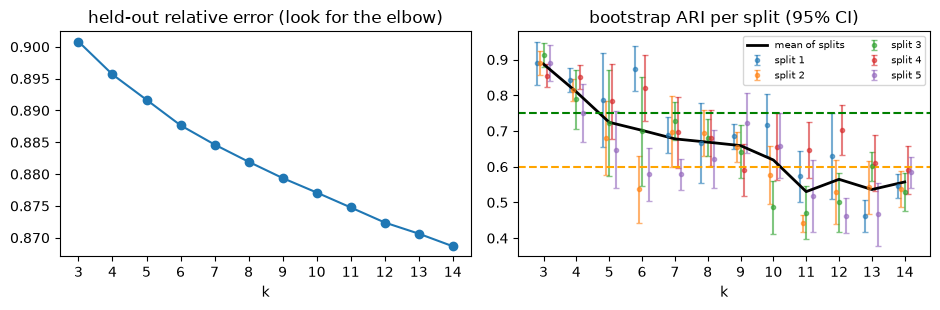

largest k with ARI >= 0.60 on 4+ of 5 splits and mean cos >= 0.75: 9
largest k with ARI >= 0.75 on 4+ of 5 splits and no unstable component (median): 4


In [20]:
import time
import io, contextlib
import os, math
import scipy.sparse as sp
from joblib import Parallel, delayed
from scipy import stats

K_GRID      = [4, 6, 8] if SMOKE else list(range(3, 15))
SPLIT_SEEDS = (1, 2) if SMOKE else (1, 2, 3, 4, 5)   # independent train / held-out splits of the cohort
N_SWEEP     = min(20_000, int(0.6 * Xs.shape[0]))      # train patients every k is fit on
N_HELD      = min(10_000, Xs.shape[0] - N_SWEEP)      # disjoint held-out patients for the error
N_BOOT_K    = 3 if SMOKE else 10          # bootstrap refits per k and split (reuses nmf_stability above)
MIN_SPLITS_OK = math.ceil(0.8 * len(SPLIT_SEEDS))   # a k must pass on this many splits (4 of 5)
N_JOBS      = max(1, (os.cpu_count() or 2) - 2)   # sklearn's NMF is single-threaded: one fit per core

def rel_err(X, W, H):
    """||X - W H||_F / ||X||_F without building the dense W @ H (X may be sparse)."""
    x2    = X.multiply(X).sum() if sp.issparse(X) else (X ** 2).sum()
    cross = np.sum((X @ H.T) * W)
    quad  = np.sum((W.T @ W) * (H @ H.T))
    return float(np.sqrt(max(x2 - 2 * cross + quad, 0.0) / x2))

def sweep_job(split_seed, k, Xtr, Xho, n_boot):
    """All metrics for one (split, k): one base fit plus n_boot bootstrap refits."""
    t0 = time.perf_counter()
    m  = NMF(n_components=k, **NMF_KW).fit(Xtr)
    Wh = m.transform(Xho)
    lab_ho = Wh.argmax(1)
    with contextlib.redirect_stdout(io.StringIO()):          # silence per-boot prints
        cos, ari, _ = nmf_stability(m, Xtr, n_boot=n_boot, n_sample=Xtr.shape[0],
                                 n_eval=Xtr.shape[0], seed=k)
    share = np.bincount(lab_ho, minlength=k) / len(lab_ho)
    return {'split': split_seed, 'k': k,
            'held_out_err': rel_err(Xho, Wh, m.components_),
            'ari_mean': ari.mean(), 'ari_sd': ari.std(ddof=1),
            'ari_se': ari.std(ddof=1) / np.sqrt(n_boot),
            'cos_mean': cos.mean(), 'n_unstable': int((cos.mean(0) < .75).sum()),
            'n_used': int((share >= .01).sum()), 'secs': time.perf_counter() - t0}

def make_split(split_seed):                                   # sliced once here, so workers get small inputs
    perm   = np.random.default_rng(split_seed).permutation(Xs.shape[0])
    tr, ho = perm[:N_SWEEP], perm[N_SWEEP:N_SWEEP + N_HELD]
    return Xs[tr], Xs[ho]

splits  = {s: make_split(s) for s in SPLIT_SEEDS}
jobs    = [(s, k) for k in sorted(K_GRID, reverse=True) for s in SPLIT_SEEDS]   # slow (large k) first
results = Parallel(n_jobs=N_JOBS, verbose=5)(
              delayed(sweep_job)(s, k, *splits[s], N_BOOT_K) for s, k in jobs)
res       = pd.DataFrame(results)
per_split = {s: res[res.split == s].drop(columns=['split', 'secs']).set_index('k').sort_index()
             for s in SPLIT_SEEDS}
print(f"{len(jobs)} jobs on {N_JOBS} workers; summed fit time {res.secs.sum() / 60:.1f} CPU-min")

# one row per k, summarised over splits
g     = pd.concat(per_split, names=['split']).groupby('k')
sweep = pd.DataFrame({'held_out_err': g.held_out_err.mean(),
                      'ari_mean': g.ari_mean.mean(), 'ari_sd_splits': g.ari_mean.std(),
                      'n_splits_solid': g.ari_mean.apply(lambda a: int((a >= .75).sum())),
                      'n_splits_sugg':  g.ari_mean.apply(lambda a: int((a >= .60).sum())),
                      'cos_mean': g.cos_mean.mean(), 'n_unstable': g.n_unstable.median(),
                      'n_used': g.n_used.min()})
display(sweep.round(3))

t_crit = stats.t.ppf(0.975, N_BOOT_K - 1)    # few refits -> t interval, not 1.96
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.2))
ax[0].plot(sweep.index, sweep.held_out_err, marker='o')
ax[0].set_title('held-out relative error (look for the elbow)')
for i, s in enumerate(SPLIT_SEEDS):                          # small x-offset so splits do not overlap
    d = per_split[s]
    ax[1].errorbar(d.index + (i - (len(SPLIT_SEEDS) - 1) / 2) * 0.1, d.ari_mean,
                   yerr=t_crit * d.ari_se, fmt='o', ms=3, capsize=2, alpha=.6, label=f'split {s}')
ax[1].plot(sweep.index, sweep.ari_mean, 'k-', lw=2, label='mean of splits')
ax[1].axhline(0.75, ls='--', c='green');  ax[1].axhline(0.60, ls='--', c='orange')
ax[1].set_title('bootstrap ARI per split (95% CI)'); ax[1].legend(fontsize=7, ncol=2)
for a in ax: a.set_xlabel('k'); a.set_xticks(sweep.index)
plt.tight_layout(); plt.show()

ok     = sweep[(sweep.n_splits_sugg >= MIN_SPLITS_OK) & (sweep.cos_mean >= .75)]
strong = sweep[(sweep.n_splits_solid >= MIN_SPLITS_OK) & (sweep.n_unstable == 0)]
print(f"largest k with ARI >= 0.60 on {MIN_SPLITS_OK}+ of {len(SPLIT_SEEDS)} splits and mean cos >= 0.75:",
      int(ok.index.max()) if len(ok) else "none")
print(f"largest k with ARI >= 0.75 on {MIN_SPLITS_OK}+ of {len(SPLIT_SEEDS)} splits and no unstable component (median):",
      int(strong.index.max()) if len(strong) else "none")

### Reading the k sweep

- **Held-out error** always falls as k grows, so the *elbow* is what matters, not the minimum.
- **ARI / cos** are the same bootstrap checks as above, now per k and per split. `ari_mean` is
  the average over splits and `ari_sd_splits` its spread; `n_splits_solid` / `n_splits_sugg` count
  the splits with ARI at or above 0.75 / 0.60. `n_unstable` is the median over splits. Stability
  usually decays as k rises; the largest k that still passes is an upper bound.
- **Same ranking on most splits:** the pattern belongs to k, not to the patients drawn. Prefer
  the largest k that is solid on at least 4 of 5 splits (`MIN_SPLITS_OK`). **Splits disagree
  (large `ari_sd_splits`), or neighbouring k overlap within their 95% intervals:** stability
  cannot separate them, so choose on clinical readability and keep the "suggestive" caveat on
  any k below 0.75.
- Compare k by the interval (`ari_se`), not by `ari_sd`. `ari_sd` is the spread across refits
  and does not shrink with more refits; `ari_se` does.
- **`n_used`** counts components that are the dominant component for at least 1% of held-out
  patients. A k where `n_used` stops growing is adding redundant or dead components.
- No single column picks k. A defensible k sits **after the error elbow and before stability
  collapses**. The final check is still
  whether the extra components read as distinct clinical bundles, as in the k=12 discussion.

### Are those components stable? Bootstrap validation of the NMF

Reading the top codes (above) checks whether a component *means* something. It does not
check whether the component would come back on a different sample of patients. This is the
NMF analogue of Day 2's KMeans bootstrap. It validates the last `nmf` fit above.

*In plain terms: re-run the NMF on random re-draws of the patients and see whether the same
code bundles show up. A bundle that keeps reappearing is real structure; one that only
appears for some draws is an accident of which patients were sampled.*

NMF component numbering is arbitrary between fits (component 3 in one run may be component 7
in the next), so each refit's components are first **matched** to the base fit's by cosine
similarity. Two outputs:

1. **Per component:** matched cosine between the base bundle and its refit counterpart.
2. **Cohort level:** ARI between the `argmax` patient labels, comparable with Day 2.

### Reading the stability table

- **`cos_mean` near 1** means the component's code bundle reappears almost unchanged in every
  resample. **Low `cos_mean` or high `cos_sd`** means the bundle depends on which patients
  happened to be drawn, so don't build a rule on it.
- The cosine cut-offs (0.90 solid, 0.75 suggestive) are working heuristics, not standards.
- **Bootstrap ARI** compares the `argmax` patient labels from each refit with the base
  labels, so it is directly comparable with Day 2's KMeans bootstrap ARI (0.75 solid, 0.60
  suggestive). A component can be stable as a *bundle* while the `argmax` *labels* are
  noisy, because soft loadings tie between bundles. High cos with low ARI is that case.
- Each refit resamples patients with replacement (about 63% distinct patients when it draws
  the whole cohort), so this is a slightly pessimistic stability estimate.
- This validates stability, not meaning. Whether a component really is a clinical bundle is
  still the read-the-top-codes judgement above.

### Final bundles at the stable k

In [21]:
# NMF factorises into non-negative PARTS, so each component reads as a set of
# co-occurring codes. Unlike SVD components you can name them.
#
# In plain terms: NMF is only allowed to add codes together, never subtract
# them, so each component ends up looking like "a bundle of codes that tend
# to show up together" -- e.g. "clomiphene + gonadotropin drugs" reads as an actual
# clinical bundle, not an abstract direction in space. That's why we print
# the top-10 codes per component below: it's how you check whether a
# component actually means something clinically, or is noise.

for k in [K_OVERRIDE or int(strong.index.max())]:
#for k in [11]:
    nmf = NMF(n_components=k, **NMF_KW).fit(Xs)
    H   = pd.DataFrame(nmf.components_, columns=nmf_cols)
    lab_k = nmf.transform(Xs).argmax(axis=1)
    dom = pd.Series(lab_k).value_counts().sort_index()
    # save the fit for reuse (Day 3 loads it instead of refitting); the tag keeps cohorts apart
    np.savez(f"nmf_k{k}_{TAG}.npz", H=H.to_numpy(), cols=np.array(H.columns, dtype=str),
             pids=np.asarray(person_ids), labels=lab_k)
    print (f"\nNMF with {k} components:")
    for c in range(k):
        n    = int(dom.get(c, 0))
        row  = H.iloc[c]
        top  = row.sort_values(ascending=False).head(10)
        share = (top / row.sum() * 100).round(1)
        # codes = [f"{name} ({pct}%)" for name, pct in share.items()]
        codes = [f"{name}" for name, pct in share.items()]
        print(f"component {c} (n={n}, {n / n_pat * 100:.1f}%): {codes}")


NMF with 4 components:
component 0 (n=995, 19.0%): ['venipuncture_for_blo__procedure__4102442_F_35-44', 'thyroid_stimulating___procedure__4246879_F_35-44', 'complete_blood_count__procedure__4319466_F_35-44', 'hemoglobin_a1c_measu__procedure__4184637_F_35-44', 'thyroid_stimulating___procedure__4246879', 'comprehensive_metabo__procedure__3661905_F_35-44', 'hemoglobin_a1c_measu__procedure__4184637', 'lipid_panel_this_pan__cpt4__2212095_F_35-44', 'venipuncture_for_blo__procedure__4102442', 'hepatitis_c_antibody__procedure__4273104_F_35-44']
component 1 (n=1526, 29.1%): ['venipuncture_for_blo__procedure__4102442_F_25-34', 'thyroid_stimulating___procedure__4246879_F_25-34', 'venipuncture_for_blo__procedure__4102442', 'complete_blood_count__procedure__4319466_F_25-34', 'thyroid_stimulating___procedure__4246879', 'periodic_comprehensi__cpt4__2514527_F_25-34', 'gonadotropin_chorion__cpt4__2212631_F_25-34', 'complete_blood_count__procedure__4319466', 'hemoglobin_a1c_measu__procedure__4184637_F_

**NMF bundles as a table** — one row per component for the underwriter review: n (%), the top-5 OMOP entities (name, vocabulary + code, concept_id, share of the bundle's patients) and two empty columns to fill in (pathway, UW suggestion). Written to `nmf_components_<cohort>_k<k>_v3.xlsx`. `RANK_BY = 'prevalence'` ranks by how many of the bundle's patients have the code instead of by NMF loading.

In [22]:
COHORT = 'letrozole'
# Export the NMF components as a table to review with the underwriters: one row per bundle, the last two columns are left empty to fill in.
import re
try:
    import openpyxl
except ImportError as e:
    raise ImportError("pip install openpyxl in this kernel's environment, then rerun this cell") from e
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter

RANK_BY = 'loading'        # 'loading' = codes that define the bundle (NMF loading); 'prevalence' = codes most patients of the bundle have
TOP_N   = 5
k_exp   = nmf.n_components_
import os; os.makedirs('outputs', exist_ok=True)
XLSX_NMF = f"outputs/nmf_components_{COHORT}_k{k_exp}_{VARIANT}.xlsx"

lab_e  = nmf.transform(Xs).argmax(1)                                   # dominant component per patient (same rule as the sizes above)
Hc     = code_H(nmf.components_)                                      # codes, not crossed columns: the crossed loadings of a code are summed over sex and band
meta   = events.drop_duplicates('tag').set_index('tag')

# TOKEN_LEVEL == 'group': a token can be a codeset tag that collapses several concepts, so there is no single concept_id to print.
# Show the tag, how many concepts it holds and its most frequent member. Concept-level and untagged tokens keep the usual text.
# (_n_members, _is_group_token, _top_member are reused by the components-json cell below.)
_n_members = events[['tag', 'concept_id']].drop_duplicates().groupby('tag').size()
def _is_group_token(tok):
    return TOKEN_LEVEL == 'group' and tok in codesets and _n_members.get(tok, 0) > 0
def _top_member(tok):
    sub = events.loc[events['tag'] == tok, ['concept_id', 'concept_name', 'vocabulary_id', 'concept_code']]
    return sub[sub['concept_id'] == sub['concept_id'].value_counts().index[0]].iloc[0]
def _group_entity(tok, prev):
    m, n = _top_member(tok), int(_n_members[tok])
    return f"{tok} [codeset: {n} concept{'s' if n != 1 else ''}; most frequent {m.vocabulary_id} {m.concept_code} {str(m.concept_name)[:40]}] ({prev:.0%} of bundle)"

def entity(tok, prev):
    if _is_group_token(tok):
        return _group_entity(tok, prev)
    r = meta.loc[tok]
    name = re.split(r' \(|;| This ', str(r.concept_name))[0].strip()
    name = name if len(name) >= 8 else str(r.concept_name)          # packs like '{6 (azithromycin ...) } Pack [Z-PAK]' would be cut to '{6'
    name = name if len(name) <= 60 else name[:60].rsplit(' ', 1)[0] + '…'
    return f"{name} [{r.vocabulary_id} {r.concept_code}] (concept_id {int(r.concept_id)}; {prev:.0%} of bundle)"

rows_e = []
for c in range(k_exp):
    members = np.flatnonzero(lab_e == c)
    prev  = pd.Series(np.asarray(Xs_tok[members].mean(axis=0)).ravel(), index=TOK_COLS)           # share of the bundle's patients with each code (plain codes)
    score = Hc.iloc[c] if RANK_BY == 'loading' else prev
    top   = score.nlargest(TOP_N).index
    rows_e.append({'Group (bundle)': f"c{c}",
                   'n (%)': f"{len(members):,} ({len(members) / len(lab_e):.1%})",
                   'Most frequently OMOP clinical entities found': "\n".join(f"{i}. {entity(t, prev[t])}" for i, t in enumerate(top, 1)),
                   'Suggested Clinical Pathway': '',
                   'UW suggestion': ''})
nmf_table = pd.DataFrame(rows_e)

F = lambda **kw: Font(name='Arial', size=10, **kw)
thin = Side(style='thin', color='D0D5DB')
wb = openpyxl.Workbook(); ws = wb.active; ws.title = f'NMF k={k_exp}'
ws.append(list(nmf_table.columns))
for j in range(1, ws.max_column + 1):
    h = ws.cell(1, j); h.font = Font(name='Arial', size=10, bold=True, color='FFFFFF')
    h.fill = PatternFill('solid', fgColor='334E68'); h.alignment = Alignment(wrap_text=True, vertical='center', horizontal='center')
ws.row_dimensions[1].height = 30
for row in nmf_table.itertuples(index=False):
    ws.append(list(row))
for i in range(2, len(nmf_table) + 2):
    ws.row_dimensions[i].height = 15 * TOP_N + 6
    for j in range(1, ws.max_column + 1):
        c_ = ws.cell(i, j); c_.font = F(bold=(j == 1)); c_.border = Border(bottom=thin)
        c_.alignment = Alignment(wrap_text=True, vertical='top', horizontal='center' if j in (1, 2) else 'left')
for j, w in enumerate([14, 16, 95, 40, 40], 1):
    ws.column_dimensions[get_column_letter(j)].width = w
ws.freeze_panes = 'B2'
ws.cell(len(nmf_table) + 3, 1, f"Source: Day 1 v3 {COHORT}, NMF k={k_exp} on {TOKEN_LEVEL}-level tokens, codesets {CODESETS_FILE} ({len(lab_e):,} patients). n (%) = patients whose dominant component is the bundle. "
        f"Entities ranked by {'NMF loading in the bundle' if RANK_BY == 'loading' else 'share of the bundle patients having the code'}; "
        "the percentage is the share of the bundle's patients with that code. The last two columns are left empty on purpose.").font = F(italic=True)
wb.save(XLSX_NMF)
print(f"wrote {os.path.abspath(XLSX_NMF)} ({k_exp} bundles)")
nmf_table


wrote /Users/esteban.correaagudelo/codeprojects/ethos_foundation_llm/nb/repr_learn_letrozole/age_sex_sensitivity/outputs/nmf_components_letrozole_k4_agesex_both.xlsx (4 bundles)


,Group (bundle),n (%),Most frequently OMOP clinical entities found,Suggested Clinical Pathway,UW suggestion
0,c0,995 (19.0%),1. Venipuncture for blood test [SNOMED 2852000...,,
1,c1,"1,526 (29.1%)",1. Venipuncture for blood test [SNOMED 2852000...,,
2,c2,"2,064 (39.4%)",1. amoxicillin 875 MG / clavulanate 125 MG Ora...,,
3,c3,653 (12.5%),1. estradiol 2 MG Oral Tablet [RxNorm 197659] ...,,


Read those out loud: do the bundles look like kinds of care (fertility treatment, pregnancy care, peri-operative oncology care), or like age strata? The names, groups and review status of **this run's** components are written in `DESCR` (the bundle cell below); Part A+ reads what age and sex did to them.

*In plain terms: NMF is only allowed to add codes together, so each component is a bundle of codes that tend to occur together. That is why the top codes are enough to name it.*

### Where do the clinical codes sit? (loadings check)

The top-5 lists can hide a code that matters but is never in a top 5. This cell takes the fertility and oncology evidence tags that `weak_labels()` uses, plus every other codeset, and shows how each code's total loading splits across the components. Each row sums to 100%.

*In plain terms: for each hand-defined clinical code, which bundle owns it, and is it concentrated in one bundle or spread thin?*

`owner` is the component with the largest share. `rank_in_owner` is the code's rank inside that component (1 = its top code). A high share with a rank in the hundreds means the code attaches to the bundle but does not define it. Only codes with a codeset tag appear.

In [23]:
K_CHECK = nmf.n_components_      # the last fit above
m8 = nmf if nmf.n_components_ == K_CHECK else NMF(n_components=K_CHECK, **NMF_KW).fit(Xs)
H8 = code_H(m8.components_)                       # crossed loadings summed over sex and band, so the columns are codes
# v3: columns of H8 are concept tokens; a codeset's loading is the SUM over the tokens it groups (a token counts in EVERY codeset it is in)
H8g = eo.group_loadings(H8, events)

# watch list comes from codesets.yaml (via eo), not hand-typed; the cohort anchor is excluded
WATCH = {
    'fertility':      eo.FERTILITY_TAGS,
    'oncology':       eo.ONCOLOGY_TAGS,
    'other codesets': [t for t in eo.CODESETS
                       if t not in eo.FERTILITY_TAGS + eo.ONCOLOGY_TAGS and t != ANCHOR],
}

rows, missing = [], []
for group, tags in WATCH.items():
    for tag in tags:
        if tag not in H8g.columns or H8g[tag].sum() == 0:
            missing.append(tag); continue
        share = H8g[tag] / H8g[tag].sum() * 100                       # this code's split across components
        own   = int(share.values.argmax())
        rows.append({'group': group, 'code': tag, **{f'c{i}': share.iloc[i] for i in range(K_CHECK)},
                     'owner': own, 'rank_in_owner': int((H8.iloc[own] > H8.iloc[own][H8.columns.intersection(list(eo.group_tokens(events, tag)))].max()).sum() + 1)})

loadings = pd.DataFrame(rows).set_index(['group', 'code'])
comp_cols = [f'c{i}' for i in range(K_CHECK)]
display(loadings.style.format({c: '{:.0f}' for c in comp_cols}).background_gradient(
        axis=1, cmap='Blues', subset=comp_cols))
print("components (n, top code):",
      {i: (int((m8.transform(Xs).argmax(1) == i).sum()), H8.iloc[i].idxmax()[:28]) for i in range(K_CHECK)})
print("codeset tags with no column (dropped by the prevalence floor, or never occur):", missing or "none")

components (n, top code): {0: (995, 'venipuncture_for_blo__proced'), 1: (1526, 'venipuncture_for_blo__proced'), 2: (2064, 'amoxicillin_875_mg_c__clinic'), 3: (653, 'estradiol_2_mg_oral___clinic')}
codeset tags with no column (dropped by the prevalence floor, or never occur): ['breast_biopsy', 'antineoplastic_drug', 'metastasis', 'ed_visit']


base fit: NMF k=4  (the `nmf` from the cell above)
200 refits; each also keeps the % of every component's loading on the 6792 sex and age columns (compared in Part A++)


  boot 20/200  3s  ARI 0.508


  boot 40/200  1s  ARI 0.894


  boot 60/200  1s  ARI 0.794


  boot 80/200  1s  ARI 0.767


  boot 100/200  1s  ARI 0.919


... (3 outputs left out)

  boot 180/200  1s  ARI 0.905


  boot 200/200  1s  ARI 0.936


,n,top_codes,cos_mean,cos_sd,cos_min,verdict
0,995,venipuncture_for_blo__procedure__4102442_F_35-...,0.993,0.011,0.919,solid
1,1526,venipuncture_for_blo__procedure__4102442_F_25-...,0.998,0.000,0.995,solid
2,2064,"amoxicillin_875_mg_c__clinical_drug__19115197,...",0.984,0.037,0.743,solid
3,653,"estradiol_2_mg_oral___clinical_drug__1548199, ...",0.962,0.067,0.489,solid



bootstrap ARI of argmax labels (200 refits): mean 0.831  sd 0.077  (Day 2 cut-offs: >=0.75 solid, >=0.60 suggestive)


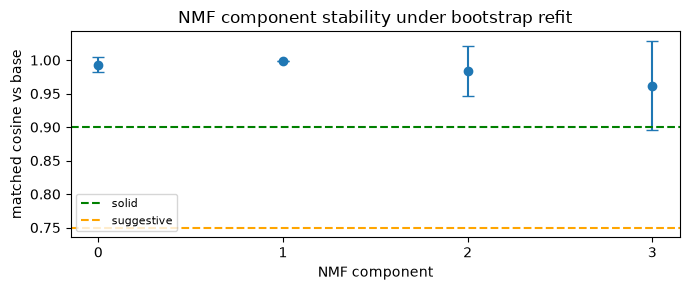

In [24]:
print(f"base fit: NMF k={nmf.n_components_}  (the `nmf` from the cell above)")
KEEP_SET = set(BLOCKS['D'][1]) if DEMO else set(BLOCKS['S'][1]) if CROSS else set()   # the sex and age band columns of the fitted matrix ('plain' has none)
KEEP     = np.array([j for j, n in enumerate(nmf_cols) if n in KEEP_SET], dtype=int)
print(f"{N_BOOT_LOAD} refits; each also keeps the % of every component's loading on the {len(KEEP)} sex and age columns (compared in Part A++)")
cos, ari, pct_keep = nmf_stability(nmf, Xs, n_boot=N_BOOT_LOAD, pct_cols=KEEP if len(KEEP) else None)

dom_n = pd.Series(nmf.transform(Xs).argmax(1)).value_counts().reindex(range(nmf.n_components_), fill_value=0)
top3  = [', '.join(pd.Series(nmf.components_[c], index=nmf_cols)
                   .nlargest(3).index) for c in range(nmf.n_components_)]
stab = pd.DataFrame({'n': dom_n.values, 'top_codes': top3,
                     'cos_mean': cos.mean(0).round(3), 'cos_sd': cos.std(0).round(3),
                     'cos_min': cos.min(0).round(3)})
stab['verdict'] = np.select([stab.cos_mean >= .90, stab.cos_mean >= .75],
                            ['solid', 'suggestive'], 'unstable')
display(stab)
print(f"\nbootstrap ARI of argmax labels ({len(ari)} refits): mean {ari.mean():.3f}  sd {ari.std():.3f}  "
      f"(Day 2 cut-offs: >=0.75 solid, >=0.60 suggestive)")

plt.figure(figsize=(7, 3))
plt.errorbar(stab.index, stab.cos_mean, yerr=stab.cos_sd, fmt='o', capsize=4)
plt.axhline(0.90, ls='--', c='green',  label='solid')
plt.axhline(0.75, ls='--', c='orange', label='suggestive')
plt.xlabel('NMF component'); plt.ylabel('matched cosine vs base')
plt.xticks(stab.index); plt.legend(fontsize=8)
plt.title('NMF component stability under bootstrap refit')
plt.tight_layout(); plt.show()

In [33]:
COHORT = 'letrozole'
# Persist the NMF components next to the .npz: n, top tokens with concept ids, a signature, and the names you give them.
# Part B of this notebook loads this file (COMP_JSON) for the component names. Workflow: run once -> copy the printed DESCR block
# (or paste names from Claude) into DESCR below -> run again. Components not listed in DESCR keep the names already saved
# in the file, as long as their top-5 tokens are unchanged.
import json, hashlib, os
FERT, ONCO, BG = 'fertility', 'oncology', 'background'
MANUAL, EXPLAINED, UNCLEAR = ('manual UW review (stage, treatment status, adjuvant letrozole)',
                              'routine (letrozole explained by fertility)',
                              'routine, indication unclear (use other evidence)')
DESCR = {
    0: dict(name='routine preventive and screening labs at age 35-44 (CBC, TSH, HbA1c, lipids, HPV, hepatitis C; 97% of its crossed loading is on 35-44)', group=BG, status=UNCLEAR),
    1: dict(name='routine preventive labs and exams at age 25-34 (venipuncture, TSH, CBC, preventive visit, gynecologic exam, quantitative hCG; 96% of its crossed loading is on 25-34)', group=BG, status=UNCLEAR),
    2: dict(name='acute-infection pharmacy (antibiotics, steroids, NSAIDs) with the oncology codes folded in: 96-100% of breast_cancer, mastectomy, radiation, lumpectomy, lymph-node and anastrozole loading sits here, so oncology cannot be read apart at k=4', group=BG, status=UNCLEAR),
    3: dict(name='fertility treatment (ART drug protocols: estradiol, progesterone, Menopur, leuprolide, Ovidrel, ganirelix) with carrier screening, ages 25-44', group=FERT, status=EXPLAINED),
}
DESCR_K = 4   # the stable k of this run (largest k with bootstrap ARI >= 0.75 on 4 of 5 splits and no unstable component); plain and extended settle on k=7. Pregnancy care, physical therapy and the oncology care pattern do not form components at k=4; with another k these names are skipped

k_j       = nmf.n_components_
if DESCR and k_j != DESCR_K:
    print(f"k={k_j}, but the names in DESCR are for k={DESCR_K}: skipped"); DESCR = {}
NPZ_J     = f"nmf_k{k_j}_{TAG}.npz"
JSON_PATH = f"nmf_k{k_j}_{TAG}_components.json"
TOP_J     = 10

Hj     = code_H(nmf.components_)
lab_j  = nmf.transform(Xs).argmax(1)
meta_j = events.drop_duplicates('tag').set_index('tag')
old    = json.load(open(JSON_PATH))['components'] if os.path.exists(JSON_PATH) else {}

comps = {}
for c in range(k_j):
    row = Hj.iloc[c]
    sig = list(row.nlargest(5).index)
    toks = []
    for t, v in row.nlargest(TOP_J).items():
        if _is_group_token(t):                      # codeset tag: no single concept (helpers defined in the components-table cell)
            m = _top_member(t)
            toks.append(dict(token=t, concept_id=None,
                             concept_name=f"[codeset {t}] {int(_n_members[t])} concepts; most frequent: {m.concept_name}",
                             vocabulary_id='codeset', concept_code='', n_concepts=int(_n_members[t]),
                             loading=round(float(v), 6), share_pct=round(float(v / row.sum() * 100), 1)))
            continue
        m = meta_j.loc[t]
        toks.append(dict(token=t, concept_id=int(m.concept_id) if pd.notna(m.concept_id) else None,
                         concept_name=str(m.concept_name), vocabulary_id=str(m.vocabulary_id), concept_code=str(m.concept_code),
                         loading=round(float(v), 6), share_pct=round(float(v / row.sum() * 100), 1)))
    n    = int((lab_j == c).sum())
    keep = old.get(str(c), {})
    keep = keep if set(keep.get('signature', [])) == set(sig) else {}            # saved names only survive if the component is unchanged
    d    = DESCR.get(c, {})
    comps[str(c)] = dict(n=n, pct=round(n / len(lab_j) * 100, 2), signature=sig,
                         name=d.get('name', keep.get('name')), group=d.get('group', keep.get('group')),
                         status=d.get('status', keep.get('status')), top_tokens=toks)

out = dict(cohort=COHORT, k=int(k_j), npz=NPZ_J,
           npz_sha256=hashlib.sha256(open(NPZ_J, 'rb').read()).hexdigest() if os.path.exists(NPZ_J) else None,
           n_patients=int(len(lab_j)), components=comps)
with open(JSON_PATH, 'w') as f:
    json.dump(out, f, indent=2, ensure_ascii=False)
print(f"saved {JSON_PATH}  (k={k_j}, {len(lab_j):,} patients)\n")

print(f"{'comp':>4} {'n':>6} {'%':>5}  name  |  top tokens")
for c, d in comps.items():
    print(f"{c:>4} {d['n']:>6} {d['pct']:5.1f}  {d['name'] or '(unnamed)'}  |  " + ', '.join(t['token'].split('__')[0] for t in d['top_tokens'][:4]))
print("\n# paste-ready DESCR (edit name / group / status, then re-run this cell):")
print("DESCR = {")
for c, d in comps.items():
    extra = f", status={d['status']!r}" if d['status'] else ''
    print(f"    {c}: dict(name={d['name']!r}, group={d['group']!r}{extra}),")
print("}")


saved nmf_k4_letrozole_agesex_both_components.json  (k=4, 5,238 patients)

comp      n     %  name  |  top tokens
   0    995  19.0  routine preventive and screening labs at age 35-44 (CBC, TSH, HbA1c, lipids, HPV, hepatitis C; 97% of its crossed loading is on 35-44)  |  venipuncture_for_blo, thyroid_stimulating, hemoglobin_a1c_measu, complete_blood_count
   1   1526  29.1  routine preventive labs and exams at age 25-34 (venipuncture, TSH, CBC, preventive visit, gynecologic exam, quantitative hCG; 96% of its crossed loading is on 25-34)  |  venipuncture_for_blo, thyroid_stimulating, complete_blood_count, periodic_comprehensi
   2   2064  39.4  acute-infection pharmacy (antibiotics, steroids, NSAIDs) with the oncology codes folded in: 96-100% of breast_cancer, mastectomy, radiation, lumpectomy, lymph-node and anastrozole loading sits here, so oncology cannot be read apart at k=4  |  amoxicillin_875_mg_c, 6_azithromycin_250_m, 21_methylprednisolon, fluconazole_150_mg_o
   3    653  12.5 

### Part A+ · What age and sex at exposure changed

Read in this order. All of it is descriptive: it shows what the age and sex features did to the components, it does not rank them.

1. **Where each component's loading sits**: its share on female and male columns and on each age band, and the age-sex stratum (at the first letrozole exposure) that dominates the component's patients. Every patient of this cohort is a woman, so the strata differ by age band only.
2. **Is a component just an age stratum?** `NMI` between the component of each patient and the patient's stratum at the first letrozole exposure: 0 means the components say nothing about age, 1 means they are the strata.
3. **Fertility and oncology groups**: how each group's loading (summed over sex and band) is split across components, and how common each group is by age band at the first letrozole exposure.
4. **Same patients, baseline run**: how the components of this fit line up with the `Letrozole_NMF_PrefixSpan_full` components (`nmf_k7_letrozole_full.npz`).

*In plain terms: after splitting every kind of care by the age the patient was when it happened, do the bundles still look like kinds of care (fertility treatment, pregnancy care, oncology care), or did they turn into "women 25-34", "women 35-44"?*

In [26]:
from sklearn.metrics import normalized_mutual_info_score, adjusted_rand_score
k_ev   = nmf.n_components_
H_full = pd.DataFrame(nmf.components_, columns=nmf_cols)
lab_ev = nmf.transform(Xs).argmax(1)

TOK_SET = set(TOK_COLS)
S_SET   = set(BLOCKS['S'][1]) if CROSS else set()
is_x    = np.array([n in S_SET for n in nmf_cols])                      # the crossed columns of the matrix
if CROSS:               # share of each component's crossed loading on each sex and each age band (a crossed name is code_sex_band)
    Hx      = H_full.loc[:, is_x]
    _p      = pd.DataFrame([n.rsplit('_', 2) for n in Hx.columns], columns=['code', 'sex', 'band'], index=Hx.columns)
    by_sex  = Hx.T.groupby(_p['sex']).sum().T
    by_sex  = by_sex.div(by_sex.sum(axis=1), axis=0) * 100
    by_band = Hx.T.groupby(_p['band']).sum().T
    by_band = (by_band.div(by_band.sum(axis=1), axis=0) * 100).reindex(columns=eo.age_band_labels(AGE_EDGES)).dropna(axis=1, how='all')
if PLAIN and CROSS:     # 'both': how much of each component's loading sits on the plain columns
    plain_pct = H_full.loc[:, ~is_x].sum(axis=1) / H_full.sum(axis=1) * 100
if DEMO:                # 'extended': how much of each component's loading sits on the sex and age band columns
    D_SET    = set(BLOCKS['D'][1])
    is_d     = np.array([n in D_SET for n in nmf_cols])
    demo_pct = H_full.loc[:, is_d].sum(axis=1) / H_full.sum(axis=1) * 100

strat = demo.reindex(person_ids)['stratum']
ok    = strat.notna().to_numpy()
rows  = []
for c in range(k_ev):
    m   = (lab_ev == c) & ok
    top = strat[m].value_counts(normalize=True)
    rows.append({'component': f'c{c}', 'n': int((lab_ev == c).sum()),
                 'top stratum at first letrozole exposure': top.index[0] if len(top) else '', '% of its patients': round(100 * top.iloc[0], 1) if len(top) else np.nan,
                 **({f'crossed loading % {s}': round(by_sex.loc[c, s], 1) for s in by_sex.columns} if CROSS else {}),
                 **({'loading % on plain columns': round(plain_pct[c], 1)} if PLAIN and CROSS else {}),
                 **({'loading % on sex and age band columns': round(demo_pct[c], 1), 'top sex / age column': H_full.loc[c, is_d].idxmax()} if DEMO else {}),
                 'top columns': ', '.join(H_full.iloc[c].nlargest(4).index.str.slice(0, 34))})
display(pd.DataFrame(rows).set_index('component'))
if CROSS:
    print("share of each component's crossed loading by age band at the event (%):")
    display(by_band.round(0).astype(int).style.background_gradient(axis=1, cmap='Blues'))
nmi = normalized_mutual_info_score(strat[ok], lab_ev[ok])
print(f"NMI(component, age-sex stratum at the first letrozole exposure) = {nmi:.3f}; the commonest stratum alone holds {100 * strat[ok].value_counts(normalize=True).iloc[0]:.1f}% of the patients")
if DEMO:
    print("'extended': the sex and age band columns carry almost the same information as the stratum, so the NMI is not independent evidence; it shows how much of the fit the sex and age band columns take (see 'loading % on sex and age band columns').")

,n,top stratum at first letrozole exposure,% of its patients,crossed loading % F,loading % on plain columns,top columns
component,,,,,,
c0,995,F|35-44,84.1,100.0,45.0,"venipuncture_for_blo__procedure__4, thyroid_st..."
c1,1526,F|25-34,91.3,100.0,45.5,"venipuncture_for_blo__procedure__4, thyroid_st..."
c2,2064,F|35-44,43.3,100.0,54.3,"amoxicillin_875_mg_c__clinical_dru, 6_azithrom..."
c3,653,F|35-44,54.2,100.0,52.1,"estradiol_2_mg_oral___clinical_dru, progestero..."


share of each component's crossed loading by age band at the event (%):


band,<25,25-34,35-44,45-54,55-64,65+
0,0,1,97,2,0,0
1,3,96,1,0,0,0
2,3,31,52,11,2,0
3,0,40,59,1,0,0


NMI(component, age-sex stratum at the first letrozole exposure) = 0.200; the commonest stratum alone holds 51.1% of the patients


In [27]:
# fertility / oncology groups: loading per component, summed over the crossed columns (sex and band) of the group's codes
WATCH_A = eo.FERTILITY_TAGS + eo.ONCOLOGY_TAGS + ['breast_cancer', 'anastrozole', 'tamoxifen']
Hp    = eo.group_loadings(code_H(nmf.components_), events)             # codes -> groups; umbrella groups included
W     = Hp.reindex(columns=[g for g in WATCH_A if g in Hp.columns])
loadsplit = (W.div(W.sum(axis=0), axis=1) * 100).T.fillna(0).round(0).astype(int)
loadsplit.columns = [f'c{i}' for i in loadsplit.columns]
print("share of each group's loading that sits in each component (rows sum to 100):")
display(loadsplit.style.background_gradient(axis=1, cmap='Blues'))
print("groups without a column (dropped by the prevalence floor, or never occur):", [g for g in WATCH_A if g not in W.columns] or "none")

# how common each group is by age band (% of the patients in the band with at least one event of the group), plain codes
_gi = [g for g in WATCH_A if g in TOK_COLS]
_pm = pd.DataFrame(Xs_tok[:, [TOK_COLS.index(g) for g in _gi]].toarray(), columns=_gi, index=person_ids)
_ab = demo.reindex(person_ids)['age_band']
print("\n% of patients with the group, by age band at the first letrozole exposure:")
display((_pm.groupby(_ab.to_numpy()).mean() * 100).reindex(eo.age_band_labels(AGE_EDGES)).round(1))

share of each group's loading that sits in each component (rows sum to 100):


,c0,c1,c2,c3
clomiphene,12,16,31,41
gonadotropin_drug,13,9,11,67
art_procedure,29,25,1,46
follicle_monitoring,37,36,9,19
ovarian_reserve_test,40,38,1,22
pregnancy_test,38,42,13,7
infertility,34,36,2,28
pcos,26,57,17,0
mastectomy,1,0,99,0
breast_biopsy,0,0,0,0


groups without a column (dropped by the prevalence floor, or never occur): ['metastasis']

% of patients with the group, by age band at the first letrozole exposure:


""
<25
25-34
35-44
45-54
55-64
65+


In [28]:
BASE_NPZ = '../nmf_k7_letrozole_full.npz'
if os.path.exists(BASE_NPZ):
    _z    = np.load(BASE_NPZ)
    _base = pd.Series(_z['labels'], index=_z['pids'])
    _both = _base.index.intersection(pd.Index(person_ids))
    _new  = pd.Series(lab_ev, index=person_ids).loc[_both]
    print(f"patients in both runs: {len(_both):,}   ARI(this k={k_ev} vs letrozole full k={_base.nunique()}) = {adjusted_rand_score(_base.loc[_both], _new):.3f}")
    display(pd.crosstab(_base.loc[_both].rename('letrozole full k=7 component'), _new.rename('this run')).style.background_gradient(axis=1, cmap='Blues'))
else:
    print(f"{BASE_NPZ} not found: run Letrozole_NMF_PrefixSpan_full first to compare against it")

patients in both runs: 5,238   ARI(this k=4 vs letrozole full k=7) = 0.326


this run,0,1,2,3
letrozole full k=7 component,,,,
0,291,420,64,0
1,25,124,1498,121
2,160,149,19,309
3,306,513,32,7
4,19,41,9,204
5,95,160,231,0
6,99,119,211,12


### Part A++ · Do the sex and age loadings differ between components?

The stability cell above refits the NMF on `N_BOOT_LOAD` re-draws of patients and matches every refit component to its base component. For every refit it also kept **how much of each component's loading sits on each sex and each age band, as a % of that component's total loading** (`pct`). So every component now has a list of pct values for sex and for age, one per refit, and comparing components means comparing those lists. All components come out of the same refit, so the lists are paired by refit.

1. **Table 1, one row per column** (each sex, each age band): are the components alike on it? Friedman test across components (the refits are the blocks): p-value, Kendall's W (0 = components alike, 1 = the same ordering of components in every refit) and the range of the component means.
2. **Table 2, component against component**, for male and for age band 35-44: mean difference in points, 95% interval over the refits, z (mean difference over its bootstrap SD), two-sided p, Holm-adjusted p across the pairs of that column, and a verdict.
3. **Table 3, age band 35-44 against each other band inside one component**: same columns, Holm across the comparisons of that component, and a Friedman test across the bands per component.
4. **Table 4, sex against the baseline male, inside each component (skipped when the cohort has no male column: this one is all women)**: difference = female - male (and unknown - male when that column exists) in points, 95% interval, z, two-sided p, Holm across the components, verdict. A positive difference means the component leans toward that sex more than toward male.
5. **Table 5, each age band against the baseline age <25, inside each component**: difference = band - `<25`, same columns, Holm across the bands of that component. A positive difference means the component carries more loading on that band than on `<25`.
6. **Table 6, is the same contrast alike across components?** One row per contrast (female - male, each band - `<25`): Friedman test across components on the paired difference, Kendall's W and the range of the component differences.

Verdict: `similar` = the 95% interval of the difference sits inside +/- `SIMILAR_REL` (25%) of the column's average pct (Tables 3-5: of that component's average pct per column of the group); `different` = Holm p < 0.05 and the mean difference is larger than that margin; anything else is `unclear`.

How to read it: the refits are re-draws of one cohort, not new samples, and each draws as many patients as the cohort has (5,238) with replacement, so the intervals are those of a standard bootstrap at this cohort size. The Friedman p-value shrinks toward 0 as refits are added, so read it with W and the difference in points. Only components that are stable in the table above (`cos_mean` >= 0.75) are compared. A mode with no sex or age columns (`'plain'`) has nothing to show. The raw lists (one pct per refit, component and column) are saved in `outputs/loading_pct_<TAG>.csv`.

*In plain terms: inside a pattern, does it lean female or male (male is the reference), and do the older bands carry more or less of it than the youngest band (<25 is the reference)? Does one pattern lean more than the others do, or are the differences no bigger than what you get from re-drawing the patients?*

In [29]:
from itertools import combinations
from scipy import stats

SIMILAR_REL = 0.25    # "similar": the 95% interval of the difference sits inside +/- this fraction of the column's average pct
ALPHA       = 0.05

if pct_keep is None:
    print(f"'{AGE_SEX_CROSS}': the matrix has no sex or age columns, nothing to compare.")
else:
    names_k = [nmf_cols[i] for i in KEEP]
    if DEMO:                                           # demo_sex_F, demo_age_35-44
        sex_of  = [n[len('demo_sex_'):] if n.startswith('demo_sex_') else None for n in names_k]
        band_of = [n[len('demo_age_'):] if n.startswith('demo_age_') else None for n in names_k]
    else:                                              # crossed column: code_sex_band
        _p = [n.rsplit('_', 2) for n in names_k]
        sex_of, band_of = [x[1] for x in _p], [x[2] for x in _p]
    SEX_L  = sorted({s for s in sex_of if s})
    BAND_L = [b for b in eo.age_band_labels(AGE_EDGES) if b in set(band_of)]

    def _by(of, labels):                               # (refits, k, labels): % of the loading on the columns with each label
        if not labels:                                 # a one-sex cohort has no sex column in 'extended'
            return np.zeros(pct_keep.shape[:2] + (0,))
        return np.stack([pct_keep[:, :, [i for i, o in enumerate(of) if o == l]].sum(axis=2) for l in labels], axis=2).astype(float)   # float64: a float32 p-value underflows to 0

    PCT    = {'sex': _by(sex_of, SEX_L), 'band': _by(band_of, BAND_L)}
    LABELS = {'sex': SEX_L, 'band': BAND_L}
    B_, K_ = pct_keep.shape[:2]
    STABLE = [c for c in range(K_) if stab.verdict.iloc[c] != 'unstable']     # the components that are compared

    rows = []
    for g in ('sex', 'band'):
        for j, l in enumerate(LABELS[g]):
            for c in range(K_):
                v = PCT[g][:, c, j]
                rows.append({'column': f'{g}:{l}', 'component': c, 'mean': v.mean(),
                             'lo': np.percentile(v, 2.5), 'hi': np.percentile(v, 97.5)})
    lists = pd.DataFrame(rows)
    os.makedirs('outputs', exist_ok=True)
    lists.to_csv(f'outputs/loading_lists_{TAG}.csv', index=False)
    pd.concat([pd.DataFrame({'refit': np.repeat(np.arange(B_), K_), 'component': np.tile(np.arange(K_), B_), 'column': f'{g}:{l}',
                             'pct': PCT[g][:, :, j].ravel()}) for g in ('sex', 'band') for j, l in enumerate(LABELS[g])]
              ).to_csv(f'outputs/loading_pct_{TAG}.csv', index=False)         # the lists themselves: one pct per refit, component and column
    print(f"{B_} refits; matched cosine below 0.75 in {(cos < .75).mean():.1%} of the refit components; "
          f"compared (stable): {STABLE}; left out: {[c for c in range(K_) if c not in STABLE] or 'none'}")
    for g, title in (('sex', 'sex'), ('band', 'age band at the letrozole exposures')):
        if not LABELS[g]:
            continue
        t = (lists[lists.column.str.startswith(g + ':')]
             .assign(cell=lambda d: d['mean'].map('{:.2f}'.format) + ' (' + d.lo.map('{:.2f}'.format) + ' to ' + d.hi.map('{:.2f}'.format) + ')')
             .pivot(index='component', columns='column', values='cell'))
        t.columns = [c.split(':', 1)[1] for c in t.columns]
        t = t[LABELS[g]]
        t.insert(0, 'stability', stab.verdict.to_numpy())
        print(f"\n% of each component's loading on {title}: mean (95% interval over the {B_} refits)")
        display(t)

200 refits; matched cosine below 0.75 in 1.0% of the refit components; compared (stable): [0, 1, 2, 3]; left out: none

% of each component's loading on sex: mean (95% interval over the 200 refits)


,stability,F
component,,
0,solid,54.85 (54.04 to 55.94)
1,solid,54.34 (53.61 to 55.13)
2,solid,45.95 (45.10 to 46.70)
3,solid,48.65 (47.60 to 49.88)



% of each component's loading on age band at the letrozole exposures: mean (95% interval over the 200 refits)


,stability,<25,25-34,35-44,45-54,55-64,65+
component,,,,,,,
0,solid,0.01 (0.00 to 0.02),0.79 (0.55 to 1.24),52.93 (51.66 to 54.62),1.12 (0.23 to 1.89),0.00 (0.00 to 0.01),0.00 (0.00 to 0.00)
1,solid,1.82 (1.46 to 2.25),51.81 (50.87 to 52.87),0.71 (0.42 to 0.95),0.00 (0.00 to 0.00),0.00 (0.00 to 0.00),0.00 (0.00 to 0.00)
2,solid,1.41 (0.83 to 2.17),14.06 (7.03 to 19.26),24.46 (19.43 to 30.20),4.89 (3.57 to 6.39),0.96 (0.65 to 1.34),0.16 (0.08 to 0.23)
3,solid,0.06 (0.01 to 0.19),20.43 (13.05 to 28.09),27.69 (20.77 to 34.63),0.45 (0.18 to 0.83),0.00 (0.00 to 0.00),0.01 (0.00 to 0.06)


In [30]:
if pct_keep is not None:
    def holm(p):
        p = np.asarray(p, float); adj = np.empty(len(p)); run = 0.0
        for r, i in enumerate(np.argsort(p)):
            run = max(run, min(1.0, (len(p) - r) * p[i])); adj[i] = run
        return adj

    def friedman(R):                                   # R: (refits, treatments) -> chi2, p, Kendall's W
        with np.errstate(all='ignore'):
            try:
                chi2, p = stats.friedmanchisquare(*R.T)
            except ValueError:
                return np.nan, np.nan, np.nan
        return chi2, p, chi2 / (R.shape[0] * (R.shape[1] - 1))

    def diff_row(d, margin):                           # d: the paired difference over the refits
        mean, sd = d.mean(), d.std(ddof=1)
        z = mean / sd if sd > 0 else (0.0 if mean == 0 else np.inf * np.sign(mean))
        return {'diff': mean, 'lo': np.percentile(d, 2.5), 'hi': np.percentile(d, 97.5), 'z': z,
                'p': 2 * stats.norm.sf(abs(z)), 'margin': margin}

    def verdicts(df):
        return ['similar' if r.lo >= -r.margin and r.hi <= r.margin
                else 'different' if r.p_holm < ALPHA and abs(r.diff) > r.margin else 'unclear' for r in df.itertuples()]

    # Table 1: is the column alike across the stable components?
    t1 = []
    for g in ('sex', 'band'):
        for j, l in enumerate(LABELS[g]):
            v = PCT[g][:, STABLE, j]                   # (refits, stable components)
            chi2, p, W = friedman(v)
            m = v.mean(axis=0)
            t1.append({'column': f'{g}:{l}', 'friedman chi2': chi2, 'p': p, 'Kendall W': W,
                       'lowest component mean': m.min(), 'highest component mean': m.max(), 'range (points)': m.max() - m.min()})
    t1 = pd.DataFrame(t1).set_index('column')
    _ok = t1.p.notna()
    t1.loc[_ok, 'p (Holm)'] = holm(t1.p[_ok])
    t1.to_csv(f'outputs/loading_tests_{TAG}.csv')

    # Table 2: component against component, male and age band 35-44
    FOCUS = [('sex', 'M'), ('band', '35-44')]
    t2 = []
    for g, l in FOCUS:
        if l not in LABELS[g]:
            continue
        v = PCT[g][:, :, LABELS[g].index(l)]
        margin = SIMILAR_REL * v[:, STABLE].mean()
        part = pd.DataFrame([{'column': f'{g}:{l}', 'a': a, 'b': b, **diff_row(v[:, a] - v[:, b], margin)} for a, b in combinations(STABLE, 2)])
        part['p_holm'] = holm(part.p)
        t2.append(part)
    t2 = pd.concat(t2, ignore_index=True)
    t2['verdict'] = verdicts(t2)
    t2.to_csv(f'outputs/loading_pairs_{TAG}.csv', index=False)

    # Table 3: age band 35-44 against each other band inside a component
    assert '35-44' in BAND_L, BAND_L
    r35 = BAND_L.index('35-44')
    t3, t3f = [], []
    for c in STABLE:
        V = PCT['band'][:, c, :]
        chi2, p, W = friedman(V)
        t3f.append({'component': c, 'friedman chi2': chi2, 'p': p, 'Kendall W': W,
                    '35-44 mean': V[:, r35].mean(), 'other bands mean': np.delete(V, r35, axis=1).mean()})
        part = pd.DataFrame([{'component': c, 'vs band': BAND_L[j], '35-44 mean': V[:, r35].mean(), 'band mean': V[:, j].mean(),
                              **diff_row(V[:, r35] - V[:, j], SIMILAR_REL * V.mean())} for j in range(len(BAND_L)) if j != r35])
        part['p_holm'] = holm(part.p)
        t3.append(part)
    t3  = pd.concat(t3, ignore_index=True)
    t3['verdict'] = verdicts(t3)
    t3f = pd.DataFrame(t3f).set_index('component')
    t3.to_csv(f'outputs/loading_bands_{TAG}.csv', index=False)

    _fmt = {'friedman chi2': '{:.1f}', 'p': '{:.2g}', 'p (Holm)': '{:.2g}', 'p_holm': '{:.2g}', 'Kendall W': '{:.2f}', 'z': '{:.1f}',
            'lowest component mean': '{:.2f}', 'highest component mean': '{:.2f}', 'range (points)': '{:.2f}',
            'diff': '{:.2f}', 'lo': '{:.2f}', 'hi': '{:.2f}', 'margin': '{:.2f}', '35-44 mean': '{:.2f}', 'band mean': '{:.2f}', 'other bands mean': '{:.2f}'}
    print(f"Table 1. Is the column alike across the {len(STABLE)} stable components? (Friedman over {B_} refits; means are % of a component's loading)")
    display(t1.style.format(_fmt, na_rep='-'))
    print("\nTable 2. Component a against component b (difference a - b in points, 95% interval over the refits, z-test p, Holm p within the column)")
    display(t2.style.format(_fmt))
    print(t2.groupby('column').verdict.value_counts().unstack(fill_value=0).to_string())
    print("\nTable 3a. Inside each component, is the age band profile flat? (Friedman across the bands)")
    display(t3f.style.format(_fmt, na_rep='-'))
    print("\nTable 3b. Age band 35-44 against each other band, same component (difference 35-44 minus band, points; verdict, Holm p)")
    display(t3.style.format(_fmt))
    _piv = t3.assign(cell=t3.verdict + ' (p ' + t3.p_holm.map('{:.2g}'.format) + ')').pivot(index='component', columns='vs band', values='cell')
    display(_piv[[b for b in BAND_L if b != '35-44']])

Table 1. Is the column alike across the 4 stable components? (Friedman over 200 refits; means are % of a component's loading)


,friedman chi2,p,Kendall W,lowest component mean,highest component mean,range (points),p (Holm)
column,,,,,,,
sex:F,578.4,4.9e-125,0.96,45.95,54.85,8.90,2.9e-124
band:<25,561.6,2.1e-121,0.94,0.01,1.82,1.82,6.3e-121
band:25-34,573.8,4.9e-124,0.96,0.79,51.81,51.02,2.5e-123
band:35-44,556.2,3.1e-120,0.93,0.71,52.93,52.23,6.2e-120
band:45-54,581.3,1.1e-125,0.97,0.00,4.89,4.89,7.9e-125
band:55-64,505.6,2.9e-109,0.84,0.00,0.96,0.96,2.9e-109
band:65+,566.0,2.4e-122,0.94,0.00,0.16,0.16,9.7e-122



Table 2. Component a against component b (difference a - b in points, 95% interval over the refits, z-test p, Holm p within the column)


,column,a,b,diff,lo,hi,z,p,margin,p_holm,verdict
0,band:35-44,0,1,52.23,50.84,53.93,63.9,0,6.61,0,different
1,band:35-44,0,2,28.47,23.89,33.08,10.8,3.4e-27,6.61,1.7e-26,different
2,band:35-44,0,3,25.24,17.68,32.51,6.2,5.6e-10,6.61,1.1e-09,different
3,band:35-44,1,2,-23.76,-29.81,-18.61,-8.1,6.9e-16,6.61,2.7e-15,different
4,band:35-44,1,3,-26.99,-33.95,-20.17,-6.9,4.9e-12,6.61,1.5e-11,different
5,band:35-44,2,3,-3.23,-14.74,9.05,-0.6,0.58,6.61,0.58,unclear


verdict     different  unclear
column                        
band:35-44          5        1

Table 3a. Inside each component, is the age band profile flat? (Friedman across the bands)


,friedman chi2,p,Kendall W,35-44 mean,other bands mean
component,,,,,
0,962.7,7e-206,0.96,52.93,0.38
1,962.1,9.5e-206,0.96,0.71,10.73
2,984.4,1.4e-210,0.98,24.46,4.30
3,979.3,1.8e-209,0.98,27.69,4.19



Table 3b. Age band 35-44 against each other band, same component (difference 35-44 minus band, points; verdict, Holm p)


,component,vs band,35-44 mean,band mean,diff,lo,hi,z,p,margin,p_holm,verdict
0,0,<25,52.93,0.01,52.93,51.66,54.62,71.1,0,2.29,0,different
1,0,25-34,52.93,0.79,52.14,50.85,53.54,71.1,0,2.29,0,different
2,0,45-54,52.93,1.12,51.82,49.74,53.98,47.2,0,2.29,0,different
3,0,55-64,52.93,0.00,52.93,51.66,54.62,71.1,0,2.29,0,different
4,0,65+,52.93,0.00,52.93,51.66,54.62,71.3,0,2.29,0,different
5,1,<25,0.71,1.82,-1.12,-1.60,-0.60,-4.1,3.9e-05,2.26,3.9e-05,similar
6,1,25-34,0.71,51.81,-51.10,-52.28,-50.06,-92.6,0,2.26,0,different
7,1,45-54,0.71,0.00,0.71,0.42,0.95,5.4,6.3e-08,2.26,2.5e-07,similar
8,1,55-64,0.71,0.00,0.71,0.42,0.95,5.4,6.4e-08,2.26,2.5e-07,similar
9,1,65+,0.71,0.00,0.71,0.42,0.95,5.4,6.4e-08,2.26,2.5e-07,similar


vs band,<25,25-34,45-54,55-64,65+
component,,,,,
0,different (p 0),different (p 0),different (p 0),different (p 0),different (p 0)
1,similar (p 3.9e-05),different (p 0),similar (p 2.5e-07),similar (p 2.5e-07),similar (p 2.5e-07)
2,different (p 1.5e-13),unclear (p 0.069),different (p 8.8e-14),different (p 1.7e-15),different (p 2.2e-16)
3,different (p 7.2e-12),unclear (p 0.36),different (p 7.2e-12),different (p 7.2e-12),different (p 7.2e-12)


In [31]:
if pct_keep is not None:
    # Tables 4-6: every level against the baseline of its group, inside each component (difference = level - baseline)
    BASELINE = {'sex': 'M', 'band': '<25'}
    _missing = [f'{g}:{b}' for g, b in BASELINE.items() if b not in LABELS[g]]
    if _missing:
        print('baseline column not in the matrix, its contrasts are skipped:', _missing)
    BASELINE = {g: b for g, b in BASELINE.items() if b in LABELS[g]}      # a group without its baseline column (sex in a one-sex cohort) has no contrast
    if not BASELINE:
        print('no baseline column in the matrix: Tables 4-6 skipped')
    else:
        t4 = []
        for g, base in BASELINE.items():
            j0 = LABELS[g].index(base)
            for c in STABLE:
                V = PCT[g][:, c, :]
                t4 += [{'group': g, 'component': c, 'level': l, 'baseline': base, 'baseline mean': V[:, j0].mean(), 'level mean': V[:, j].mean(),
                        **diff_row(V[:, j] - V[:, j0], SIMILAR_REL * V.mean())} for j, l in enumerate(LABELS[g]) if j != j0]
        t4 = pd.DataFrame(t4)
        # Holm family: a sex level across the components; an age band across the bands of one component
        fam = pd.Series(np.where(t4.group == 'sex', 'sex|' + t4.level, 'band|' + t4.component.astype(str)), index=t4.index)
        t4['p_holm'] = t4.groupby(fam).p.transform(holm)
        t4['verdict'] = verdicts(t4)
        t4.to_csv(f'outputs/loading_baseline_{TAG}.csv', index=False)

        t6 = []                                        # is the same contrast alike across the stable components?
        for g, base in BASELINE.items():
            j0 = LABELS[g].index(base)
            for j, l in enumerate(LABELS[g]):
                if j == j0:
                    continue
                D = PCT[g][:, STABLE, j] - PCT[g][:, STABLE, j0]        # (refits, stable components)
                chi2, p, W = friedman(D); m = D.mean(axis=0)
                t6.append({'contrast': f'{g}:{l} - {base}', 'friedman chi2': chi2, 'p': p, 'Kendall W': W,
                           'lowest component diff': m.min(), 'highest component diff': m.max()})
        t6 = pd.DataFrame(t6).set_index('contrast')
        _ok = t6.p.notna()
        t6.loc[_ok, 'p (Holm)'] = holm(t6.p[_ok])
        t6.to_csv(f'outputs/loading_baseline_alike_{TAG}.csv')

        _fmt.update({'baseline mean': '{:.2f}', 'level mean': '{:.2f}', 'lowest component diff': '{:.2f}', 'highest component diff': '{:.2f}'})
        if 'sex' in BASELINE:
            print(f"Table 4. Sex against the baseline {BASELINE['sex']}, inside each component (difference = level - baseline in points, "
                  f"95% interval over {B_} refits, z-test p, Holm p across the components)")
        if 'sex' in BASELINE:
            display(t4[t4.group == 'sex'].drop(columns='group').style.format(_fmt))
        if 'band' in BASELINE:
            print(f"\nTable 5. Age band against the baseline {BASELINE['band']}, inside each component (Holm p across the bands of the component)")
            display(t4[t4.group == 'band'].drop(columns='group').style.format(_fmt))
            _piv = (t4[t4.group == 'band'].assign(cell=lambda d: d.verdict + ' (p ' + d.p_holm.map('{:.2g}'.format) + ')')
                    .pivot(index='component', columns='level', values='cell'))
            display(_piv[[b for b in BAND_L if b != BASELINE['band']]])
        print(t4.groupby(['group', 'level']).verdict.value_counts().unstack(fill_value=0).to_string())
        print("\nTable 6. Is the same contrast alike across the stable components? (Friedman on the paired difference over the refits)")
        display(t6.style.format(_fmt, na_rep='-'))

baseline column not in the matrix, its contrasts are skipped: ['sex:M']

Table 5. Age band against the baseline <25, inside each component (Holm p across the bands of the component)


,component,level,baseline,baseline mean,level mean,diff,lo,hi,z,p,margin,p_holm,verdict
0,0,25-34,<25,0.01,0.79,0.78,0.55,1.23,3.3,0.00082,2.29,0.0033,similar
1,0,35-44,<25,0.01,52.93,52.93,51.66,54.62,71.1,0,2.29,0,different
2,0,45-54,<25,0.01,1.12,1.11,0.23,1.88,2.7,0.0072,2.29,0.022,similar
3,0,55-64,<25,0.01,0.00,-0.01,-0.02,0.01,-0.8,0.45,2.29,0.48,similar
4,0,65+,<25,0.01,0.00,-0.01,-0.02,-0.00,-1.2,0.24,2.29,0.48,similar
5,1,25-34,<25,1.82,51.81,49.99,48.79,51.41,78.4,0,2.26,0,different
6,1,35-44,<25,1.82,0.71,-1.12,-1.60,-0.60,-4.1,3.9e-05,2.26,3.9e-05,similar
7,1,45-54,<25,1.82,0.00,-1.82,-2.25,-1.46,-9.0,1.9e-19,2.26,7.4e-19,similar
8,1,55-64,<25,1.82,0.00,-1.82,-2.25,-1.46,-9.0,1.9e-19,2.26,7.4e-19,similar
9,1,65+,<25,1.82,0.00,-1.82,-2.25,-1.46,-9.0,1.9e-19,2.26,7.4e-19,similar


level,25-34,35-44,45-54,55-64,65+
component,,,,,
0,similar (p 0.0033),different (p 0),similar (p 0.022),similar (p 0.48),similar (p 0.48)
1,different (p 0),similar (p 3.9e-05),similar (p 7.4e-19),similar (p 7.4e-19),similar (p 7.4e-19)
2,different (p 2.7e-05),different (p 3.6e-13),different (p 0.0004),similar (p 0.18),unclear (p 0.0002)
3,different (p 3e-06),different (p 1.2e-11),similar (p 0.065),similar (p 1),similar (p 1)


verdict      different  similar  unclear
group level                             
band  25-34          3        1        0
      35-44          3        1        0
      45-54          1        3        0
      55-64          0        4        0
      65+            0        3        1

Table 6. Is the same contrast alike across the stable components? (Friedman on the paired difference over the refits)


,friedman chi2,p,Kendall W,lowest component diff,highest component diff,p (Holm)
contrast,,,,,,
band:25-34 - <25,579.0,3.5e-125,0.97,0.78,49.99,1.4e-124
band:35-44 - <25,563.8,7e-122,0.94,-1.12,52.93,1.4e-121
band:45-54 - <25,581.5,1e-125,0.97,-1.82,3.49,5.2e-125
band:55-64 - <25,534.0,2e-115,0.89,-1.82,-0.01,2e-115
band:65+ - <25,575.6,1.9e-124,0.96,-1.82,-0.01,5.8e-124


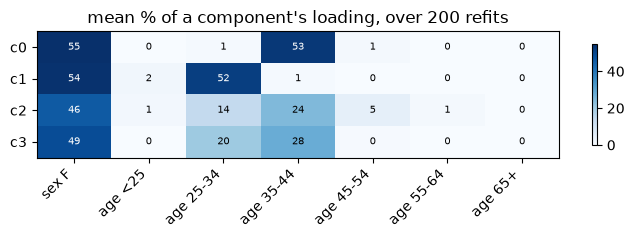

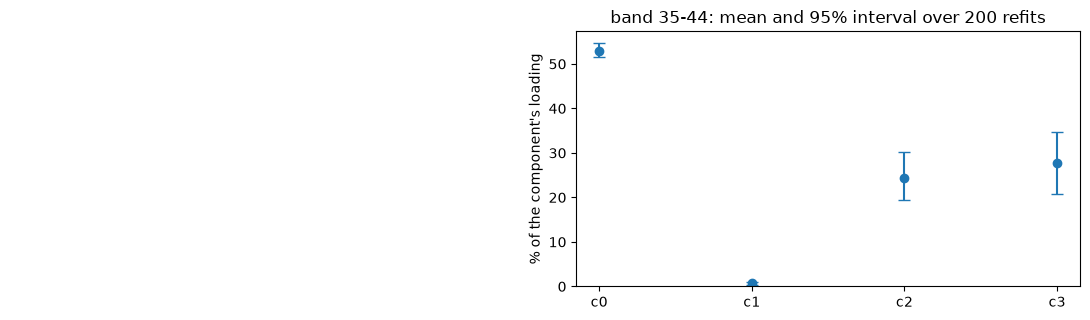

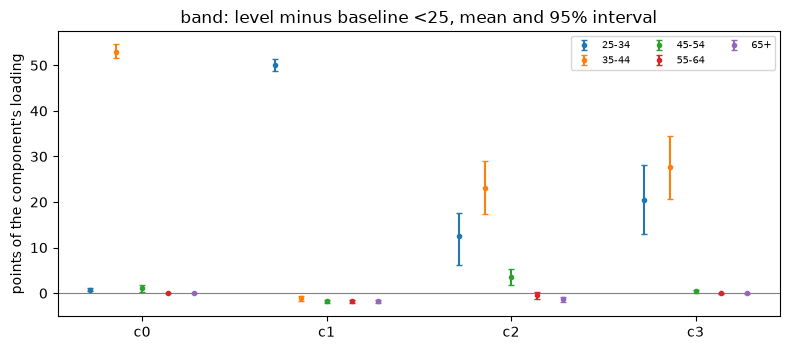

In [32]:
if pct_keep is not None:
    # mean % of each component's loading on every sex and age band (left) and the age at the first letrozole exposure by component (right)
    M = np.concatenate([PCT['sex'].mean(0), PCT['band'].mean(0)], axis=1)
    cols_h = [f'sex {s}' for s in SEX_L] + [f'age {b}' for b in BAND_L]
    w_h = 1.5 + 0.8 * len(cols_h)                  # width of the heatmap; the age density takes the right-hand panel
    fig, (a, d) = plt.subplots(1, 2, figsize=(w_h + 4.8, 0.8 + 0.42 * K_), gridspec_kw={'width_ratios': [w_h, 4.8]})
    im = a.imshow(M, cmap='Blues', aspect='auto')
    a.set_xticks(range(len(cols_h)), cols_h, rotation=45, ha='right')
    a.set_yticks(range(K_), [f'c{c}' + ('' if c in STABLE else ' (unstable)') for c in range(K_)])
    for i in range(K_):
        for j in range(len(cols_h)):
            a.text(j, i, f'{M[i, j]:.2f}' if M.max() < 10 else f'{M[i, j]:.0f}', ha='center', va='center', fontsize=7,
                   color='white' if M[i, j] > 0.6 * M.max() else 'black')
    a.set_title(f"mean % of a component's loading, over {B_} refits")
    plt.colorbar(im, ax=a, shrink=.8)

    # right: age at the first letrozole exposure, one density curve per component (its patients = those whose largest weight is that component)
    _age = demo.reindex(person_ids)['age'].to_numpy()
    _ok  = np.isfinite(_age)
    _x   = np.linspace(np.nanpercentile(_age, 0.5) - 2, np.nanpercentile(_age, 99.5) + 2, 300)
    for c in range(K_):
        _a = _age[(lab_ev == c) & _ok]
        if len(_a) > 2 and _a.std() > 0:
            d.plot(_x, stats.gaussian_kde(_a)(_x), color=f'C{c % 10}', lw=1.4, ls='-' if c in STABLE else ':', label=f'c{c} (n={len(_a):,})')
    d.plot(_x, stats.gaussian_kde(_age[_ok])(_x), color='k', lw=1, ls='--', label=f'all patients (n={_ok.sum():,})')
    for e in AGE_EDGES:                              # the band edges of the columns on the left
        d.axvline(e, color='lightgrey', lw=.8, zorder=0)
    d.set_xlabel('age (years) at the first letrozole exposure'); d.set_ylabel('density')
    d.set_xlim(_x[0], _x[-1]); d.set_title('age at the first exposure, by component')
    d.legend(fontsize=7, ncol=2 if K_ > 6 else 1, loc='upper right')
    plt.tight_layout(); plt.show()

    # the two columns of Table 2, component by component, with the 95% interval over the refits
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
    for a, (g, l) in zip(ax, FOCUS):
        if l not in LABELS[g]:
            a.axis('off'); continue
        v = PCT[g][:, :, LABELS[g].index(l)]
        mean = v.mean(0); lo, hi = np.percentile(v, [2.5, 97.5], axis=0)
        for c in range(K_):
            a.errorbar(c, mean[c], yerr=[[max(mean[c] - lo[c], 0)], [max(hi[c] - mean[c], 0)]], fmt='o', capsize=4,
                       color='C0' if c in STABLE else 'lightgrey')
        a.set_xticks(range(K_), [f'c{c}' for c in range(K_)]); a.set_ylabel("% of the component's loading")
        a.set_title(f'{g} {l}: mean and 95% interval over {B_} refits'); a.set_ylim(bottom=0)
    plt.tight_layout(); plt.show()

    # Tables 4 and 5: each level minus its baseline, component by component
    if 't4' in globals():
        fig, ax = plt.subplots(1, len(BASELINE), figsize=(12 if len(BASELINE) > 1 else 8, 3.6), squeeze=False)
        for a, g in zip(ax[0], BASELINE):
            d = t4[t4.group == g]
            levels = [l for l in LABELS[g] if l != BASELINE[g]]
            for n, l in enumerate(levels):
                dd = d[d.level == l]
                x = dd.component.to_numpy() + (n - (len(levels) - 1) / 2) * 0.14
                a.errorbar(x, dd['diff'], yerr=[(dd['diff'] - dd.lo).clip(lower=0), (dd.hi - dd['diff']).clip(lower=0)],
                           fmt='o', ms=3, capsize=2, color=f'C{n}', label=l)
            a.axhline(0, color='grey', lw=.8)
            a.set_xticks(STABLE, [f'c{c}' for c in STABLE]); a.set_ylabel("points of the component's loading")
            a.set_title(f"{g}: level minus baseline {BASELINE[g]}, mean and 95% interval"); a.legend(fontsize=7, ncol=3)
        plt.tight_layout(); plt.show()

# Part B · Day 3 — sequence motifs inside the NMF bundles

## Mini Table 1 · letrozole cohort by confirmed breast-cancer diagnosis

**Confirmed breast cancer** = a patient with *any* condition row matching **ICD-9 174.x**, **ICD-10 C50.x** or
**SNOMED concept 4162253** (primary malignant neoplasm of breast). Everyone else is "no breast cancer dx".
The extract keeps standard concepts only, so ICD codes are not in `concept.csv`; they are read from the raw
`condition_source_value` column, which `load_events()` drops. The `breast_cancer` tag used elsewhere in this notebook
is the narrower, name-matched codeset, so the two counts differ (see the "meets" rows).

In [ ]:
cond = pd.read_csv(os.path.join(OUT_DIR, 'master_condition_occurrence.csv'),
                   usecols=['person_id', 'condition_concept_id', 'condition_source_value', 'condition_start_date'],
                   dtype={'condition_source_value': str}, parse_dates=['condition_start_date'])
src  = cond.condition_source_value.fillna('').str.upper().str.replace('.', '', regex=False)   # 'C50.911' -> 'C50911'
crit = {'ICD-9 174.x':     src.str.startswith('174'),
        'ICD-10 C50.x':    src.str.startswith('C50'),
        'SNOMED 4162253':  cond.condition_concept_id.eq(4162253)}

cohort_ids = set(events.person_id)
case_mask  = np.logical_or.reduce(list(crit.values()))
case_ids   = set(cond.person_id[case_mask]) & cohort_ids
groups = {'Overall': cohort_ids,
          'No breast cancer dx': cohort_ids - case_ids,
          'Confirmed breast cancer dx': case_ids}

lz        = eo.index_dates(events, 'letrozole').set_index('person_id')['index_date']
age_yrs   = (lz - person.set_index('person_id')['birth_date'].reindex(lz.index)).dt.days / 365.25
female    = set(person.loc[person.gender.astype(str).str.upper().eq('FEMALE'), 'person_id'])
first_dx  = cond[case_mask].groupby('person_id').condition_start_date.min()       # first confirmed dx per patient
crit_ids  = {k: set(cond.person_id[m]) & cohort_ids for k, m in crit.items()}

# diagnosis-related rows: curated codesets whose events are conditions
ev_c      = events[events.group.notna()]
tag_dom   = ev_c.assign(g=ev_c.groups.astype(str).str.split('|')).explode('g').groupby('g').domain.agg(lambda s: s.mode().iat[0])
DX_TAGS   = sorted(tag_dom.index[tag_dom == 'Condition'])
has       = {t: set(ev_c.loc[eo.group_mask(ev_c, t), 'person_id']) for t in DX_TAGS}

def describe(name, ids):
    n   = len(ids)
    npc = lambda k: f"{k} ({k / n:.1%})" if n else "0"
    a   = age_yrs.reindex(list(ids))
    row = {'N (% of cohort)': f"{n} ({n / len(cohort_ids):.1%})",
           'Age at first letrozole, mean (SD)': f"{a.mean():.1f} ({a.std():.1f})" if n else '-',
           'Female, n (%)': npc(len(ids & female))}
    for k, s in crit_ids.items():
        row[f'Meets {k}, n (%)'] = npc(len(ids & s))
    before = [first_dx.get(p) is not None and first_dx[p] < lz[p] for p in ids]
    row['Dx recorded before first letrozole, n (%)'] = npc(sum(before)) if name == 'Confirmed breast cancer dx' else '-'
    for t in DX_TAGS:
        row[f'{t}, n (%)'] = npc(len(ids & has[t]))
    return row

table1 = pd.DataFrame({name: describe(name, ids) for name, ids in groups.items()})
display(table1)
print("curated diagnosis codesets shown:", DX_TAGS)

In [ ]:
seqs = eo.sequences(events, col='tag', dedup_same_day=True, collapse_repeats=True)
pids = sorted(seqs)
db   = [seqs[p] for p in pids]

print("example timeline:")
print(' -> '.join(db[1][:12]))
print("\nmedian sequence length:", int(np.median([len(s) for s in db])))

### The preprocessing decisions, restated

The first two live in `eo.sequences()` and both are arbitrary:

1. **Same-day ties.** Claims carry a date, not a timestamp, so `DOMAIN_ORDER` breaks ties.
   Visit, condition, procedure, measurement, drug, observation.
2. **Refill collapsing.** Consecutive repeats of the same tag become one token, otherwise
   every pattern is `metformin -> metformin -> metformin`. Chronicity is real signal, so
   capture it as a separate feature — fill count, days supply — not as sequence position.
3. **Visits are not in the sequence at all (v2).** In v1 pharmacy visits were the most common
   tokens (`pharmacy__visit__38004338`) and made every motif list a chain of pharmacy / office
   visits. Dropping them removes that care-setting bias. Visit-borne signal is invisible here by
   construction (Day 1 v2 found no curated tag sitting on a visit concept, so no codeset tag is lost).

## 1 · PrefixSpan, implemented

In [ ]:
import collections

def prefixspan(db, min_sup, max_len=4):
    """Minimal PrefixSpan over single-item sequences.

    db      : list of lists of tokens
    min_sup : minimum number of sequences containing the pattern
    returns : DataFrame of (pattern, support, support_pct)
    """
    n, results = len(db), []

    def scan(projected, prefix):
        counts = collections.Counter()
        for seq in projected:
            for item in sorted(set(seq)):                   # count each sequence once
                counts[item] += 1
        for item, c in counts.items():
            if c < min_sup:
                continue
            new_prefix = prefix + [item]
            results.append((tuple(new_prefix), c))
            if len(new_prefix) >= max_len:
                continue
            # project: keep the suffix after the FIRST occurrence of item
            nxt = [seq[seq.index(item) + 1:] for seq in projected if item in seq]
            if nxt:
                scan(nxt, new_prefix)

    scan([list(s) for s in db], [])
    return (pd.DataFrame(results, columns=['pattern', 'support'])
              .assign(support_pct=lambda d: (d.support / n * 100).round(1)))

## 2 · Discriminative mining — motifs per NMF component

Raw support finds whatever is common, which is mostly ambient care. What you want is patterns
common **inside** a group and rare **outside** it. Here the groups are the **NMF components of
`Day1_nmf_v3`** (k=7 on concept-level tokens, visits pruned).

What the v2 components look like (top codes and the Day 1 v2 fertility / oncology cross-tab):

- **Fertility, four bundles:** treatment c2 (gonadotropins, GnRH agonist, ART), carrier screening c4,
  prenatal labs c7 (ABO / Rh), pregnancy outcome c0.
- **Oncology, one bundle: c5.** Its top codes are peri-operative (ondansetron / ketorolac injectables,
  fentanyl, propofol), but it holds 62% of the breast-cancer-only patients. It is small, so read it as a lower bound.
- **Background, c1, c3, c6:** acute-infection pharmacy (antibiotics, steroids, NSAIDs), preventive
  labs (lipids, HbA1c, TSH, vitamin D), therapeutic / manual procedures (PT, chiropractic).
  Without visit tokens c1 is no longer "pharmacy visits" but the drugs themselves.

Day 3 asks what order those codes come in, per component. The draft triage (needs underwriter
review) is printed next to each component below.

In [ ]:
# Part B starts from the NMF fitted in Part A (same events, same prevalence floor, same anchor drop): no refit, no cache file.
K    = nmf.n_components_
H_full = pd.DataFrame(nmf.components_, columns=nmf_cols)   # the columns the NMF was fitted on (Part A+ reads this one)
H    = code_H(nmf.components_)                             # Part B names codes: crossed loadings summed over sex and band
lab  = pd.Series(nmf.transform(Xs).argmax(1), index=person_ids)
comp = lab.reindex(pids).fillna(-1).astype(int).to_numpy()   # aligned with db / pids

# DRAFT triage labels -- need underwriter review.
FERT, ONCO, BG = 'fertility', 'oncology', 'background'
MANUAL, EXPLAINED, UNCLEAR = ('manual UW review (stage, treatment status, adjuvant letrozole)',
                              'routine (letrozole explained by fertility)',
                              'routine, indication unclear (use other evidence)')
COMP = {}                                                     # auto-names from the top tokens; real names come from the components JSON below
for c in range(K):
    top = H.iloc[c].idxmax()
    COMP[c] = (top[:20], f'c{c}: ' + ', '.join(H.iloc[c].nlargest(3).index.str.split('__').str[0]), BG, UNCLEAR)
# Names from the components JSON written by the last cell of Part A: override COMP for every component whose top-5 tokens still match
# (>= 4 of 5); otherwise the auto-name is kept and a warning is printed. Point COMP_JSON at another file to reuse it.
import json
COMP_JSON = f"nmf_k{K}_{TAG}_components.json"
if os.path.exists(COMP_JSON):
    J = json.load(open(COMP_JSON))['components']
    for c in range(K):
        j = J.get(str(c))
        if not j or not j.get('name'):
            continue
        if len(set(j['signature']) & set(H.iloc[c].nlargest(5).index)) < 4:
            print(f"WARNING c{c}: top tokens in {COMP_JSON} differ from this NMF, its name is ignored")
            continue
        COMP[c] = (COMP[c][0], j['name'], j.get('group') or COMP[c][2]) + ((j.get('status') or COMP[c][3],) if len(COMP[c]) > 3 else ())
    print(f"component names loaded from {COMP_JSON}")
else:
    print(f"{COMP_JSON} not found: components are auto-named (name them in DESCR in the last cell of Part A)")
print("top tokens per component:")
for c in range(K):
    print(f"  c{c}:", ', '.join(H.iloc[c].nlargest(4).index.str.slice(0, 32)))

print(f"{'comp':>4} {'n':>6} {'%':>5}  {'group':<24} name")
for c, v in COMP.items():
    n = int((comp == c).sum())
    print(f"{c:>4} {n:>6} {n / len(comp) * 100:5.1f}  {v[2]:<24} {v[1]}")


In [ ]:
from joblib import Parallel, delayed

def contains(seq, pat):
    it = iter(seq)
    return all(x in it for x in pat)

def discriminative(mask, candidates, sequences_db=None, min_in=0.12):
    sdb = sequences_db if sequences_db is not None else db
    out = []
    for p in candidates:
        h = np.array([contains(s, p) for s in sdb])
        si, so = h[mask].mean(), h[~mask].mean()
        if si >= min_in:
            out.append({'pattern': ' -> '.join(p), 'sup_in': round(si, 3),
                        'sup_out': round(so, 3), 'lift': round((si + .01) / (so + .01), 1)})
    if not out:
        return pd.DataFrame(columns=['pattern', 'sup_in', 'sup_out', 'lift'])
    return pd.DataFrame(out).sort_values(['lift', 'pattern'], ascending=[False, True]).reset_index(drop=True)

def _component_job(sdb_in, sdb_out, rel_sup, max_cand):
    """One component: LOCAL mining on its own patients, then lift vs the out-sample.
    Takes only its own slices, so it ships cheaply to a worker process."""
    pats_c = prefixspan(sdb_in, max(3, int(rel_sup * len(sdb_in))), max_len=4)
    pats_c = pats_c[pats_c.pattern.map(len) >= 3].sort_values(['support', 'pattern'], ascending=[False, True]).head(max_cand)
    sdb    = sdb_in + sdb_out
    mask   = np.arange(len(sdb)) < len(sdb_in)
    return discriminative(mask, [tuple(p) for p in pats_c.pattern], sequences_db=sdb, min_in=rel_sup)

def component_motifs(rel_sup=0.15, max_cand=100, n_out=1500, seed=0, n_jobs=None):
    """All components in parallel (they are independent), like Day 1's k-sweep."""
    n_jobs = n_jobs or min(len(COMP), max(1, (os.cpu_count() or 2) - 2))   # leave 2 cores free
    jobs = []
    for c in COMP:
        idx_in  = np.flatnonzero(comp == c)
        idx_out = np.flatnonzero(comp != c)
        idx_out = np.random.default_rng(seed).choice(idx_out, min(n_out, len(idx_out)), replace=False)
        jobs.append(delayed(_component_job)([db[i] for i in idx_in], [db[i] for i in idx_out],
                                            rel_sup, max_cand))
    return dict(zip(COMP, Parallel(n_jobs=n_jobs, verbose=5)(jobs)))

# the local mining is the point: a global 4% floor would bury the 5% components entirely
motifs = component_motifs()
for c, (_, name, grp, triage) in COMP.items():
    d = motifs[c]
    print(f"\n===== component {c} [{grp}]: {name}  (n={(comp == c).sum()})")
    print(f"      draft triage: {triage}")
    if len(d):
        display(d.head(4))
    else:
        print("  no ordered pattern of length >= 3 reaches the in-component support floor")

Each component now has **candidate motifs attached** — an ordered sequence, not just a set of
prevalent codes. Things to check:

- Does **c5** read as a cancer-treatment path (workup -> surgery / chemo -> endocrine drug)? Without
  visits, the peri-operative injectables carry the "surgery happened" step on their own.
- Do the fertility bundles (c0, c2, c4, c7) read as distinct stages — screening, stimulation, pregnancy,
  prenatal labs — rather than one blob?
- Do the background bundles (c1, c3, c6) stay generic, or reveal a hidden indication now that the
  pharmacy-visit chains are gone?

### A second lens: the Day 1 fertility / oncology probe

`weak_labels()` gives a direct, rule-based split of the indication, built from corroborating
co-evidence only. It is a probe, not the structure: it labels only part of the cohort, and
oncology is tiny next to fertility (see the counts printed below), so the eight components
above are the primary view and this is a cross-check.

Caveat: the probe labels come from `FERTILITY_TAGS` / `ONCOLOGY_TAGS`, so a motif made of those
same tags partly rediscovers the label rule. Read the motifs that *add* something around them.

In [ ]:
weak = eo.weak_labels(events)
wl   = weak.set_index('person_id').weak_label

# Every patient here has letrozole by cohort construction, so no filtering needed. Still use
# LOCAL mining: a global 4% threshold is tuned for the full mixed cohort, and the smaller
# indication subgroup would be buried under it.
y_lz = np.array([wl.get(p, 'unlabelled') for p in pids])
print("letrozole patients:", len(db),
      "  labelled:", int((y_lz != 'unlabelled').sum()),
      "  ", dict(zip(*np.unique(y_lz, return_counts=True))))

pats_lz = prefixspan(db, max(3, int(0.08 * len(db))), max_len=4)
C_lz = [tuple(p) for p in pats_lz[pats_lz.pattern.map(len) >= 3]
        .sort_values(['support', 'pattern'], ascending=[False, True]).head(60).pattern]

for g in ['fertility', 'oncology']:
    print(f"\n=== {g} indication")
    display(discriminative(y_lz == g, C_lz, sequences_db=db, min_in=0.10).head(4))

## 2b · Are the motifs stable?

Section 2 mined each component **once**, on one fixed sample, so every `lift` above is a single number.
Day 1 asked the same question of the NMF (`nmf_stability`, five split seeds, "solid on 4+ of 5"). Same idea here,
two tiers, because there are two different questions:

1. **Bootstrap — is the *lift number* steady?** Resample the component's patients (and the outside sample) with
   replacement 1,000 times and recompute `sup_in`, `sup_out`, `lift` for the same candidate motifs. Gives a 95%
   range for lift. Cheap: no re-mining.
2. **Split seeds — would the *motif itself* be found again?** Split each component's patients 50 / 50 at random.
   Mine on one half, score on the held-out half, repeat for 5 seeds. A motif counts as **replicated** in a split if
   it is nominated on the train half **and** still reaches the support floor and `lift >= MIN_LIFT` on the
   held-out half. Different seeds can nominate different candidates, so this also tests the candidate step.

```
 component's patients ──┬─ bootstrap x1000 (same candidates)  ->  lift_lo ... lift_hi
                        └─ split seed s=1..5:  [ train half | held-out half ]
                                                 mine here     score here    ->  splits_found (0-5)
```

Verdict, same words as Day 1: **solid** = replicated in 4+ of 5 splits and `lift_lo >= MIN_LIFT`;
**suggestive** = 3 of 5; otherwise **unstable**.

In [ ]:
import collections, time

MIN_LIFT      = 2                       # a motif must be at least this specific to its component
MIN_SPLITS_OK = 4                       # of the 5 split seeds, as in Day 1
REL_SUP, N_OUT, SEED = 0.15, 1500, 0    # the values component_motifs() used above (same candidates, same outside sample)

# Hit matrix, built once and shared by the bootstrap: hits[c][i, j] = does motif i occur in patient j?
# Columns are [in-component patients | the same random outside sample component_motifs() drew].
hits, n_in = {}, {}
for c in COMP:
    cand    = [tuple(p.split(' -> ')) for p in motifs[c].pattern]
    idx_in  = np.flatnonzero(comp == c)
    idx_out = np.flatnonzero(comp != c)
    idx_out = np.random.default_rng(SEED).choice(idx_out, min(N_OUT, len(idx_out)), replace=False)
    sdb     = [db[i] for i in np.concatenate([idx_in, idx_out])]
    hits[c] = np.array([[contains(s, p) for s in sdb] for p in cand], dtype=bool).reshape(len(cand), len(sdb))
    n_in[c] = len(idx_in)
print({c: hits[c].shape for c in COMP})

In [ ]:
B = 1000   # bootstrap draws

def bootstrap_lift(H, n_in, B=B, seed=0):
    """Lift of every motif (rows of H) on B resamples with replacement of the in / out patients."""
    rng        = np.random.default_rng(seed)
    Hin, Hout  = H[:, :n_in], H[:, n_in:]
    n_out      = Hout.shape[1]
    lifts      = np.empty((B, H.shape[0]))
    for b in range(B):
        si = Hin[:,  rng.integers(0, n_in,  n_in)].mean(1)
        so = Hout[:, rng.integers(0, n_out, n_out)].mean(1)
        lifts[b] = (si + .01) / (so + .01)
    return lifts

boot = {}
for c in COMP:
    d = motifs[c].copy()
    if len(d):
        L = bootstrap_lift(hits[c], n_in[c])
        d['lift_lo'], d['lift_hi'] = np.percentile(L, [2.5, 97.5], axis=0).round(1)
        d['p_lift_ok'] = (L >= MIN_LIFT).mean(0).round(2)     # share of draws where lift >= MIN_LIFT
    boot[c] = d
print("bootstrap done:", {c: len(d) for c, d in boot.items()}, "motifs per component")

In [ ]:
SPLIT_SEEDS = (1, 2, 3, 4, 5)   # independent 50 / 50 splits of each component, as in Day 1
MAX_CAND    = 100                # same candidate budget as component_motifs()

def _split_job(sdb_tr, sdb_ho, sdb_out, rel_sup, max_cand):
    """One (component, seed): nominate candidates by mining the TRAIN half, score them on the HELD-OUT half
    against a seed-specific outside sample. discriminative() already drops motifs below the support floor."""
    pats = prefixspan(sdb_tr, max(3, int(rel_sup * len(sdb_tr))), max_len=4)
    pats = pats[pats.pattern.map(len) >= 3].sort_values(['support', 'pattern'], ascending=[False, True]).head(max_cand)
    sdb  = sdb_ho + sdb_out
    mask = np.arange(len(sdb)) < len(sdb_ho)
    return discriminative(mask, [tuple(p) for p in pats.pattern], sequences_db=sdb, min_in=rel_sup)

def split_stability(n_out=N_OUT, n_jobs=None):
    """All (component, seed) jobs in parallel, largest component first so no big job starts last."""
    n_jobs = n_jobs or max(1, (os.cpu_count() or 2) - 2)
    keys, jobs = [], []
    for c in sorted(COMP, key=lambda c: -int((comp == c).sum())):
        idx_in, idx_out = np.flatnonzero(comp == c), np.flatnonzero(comp != c)
        for s in SPLIT_SEEDS:
            rng  = np.random.default_rng(s)
            perm = rng.permutation(idx_in)
            tr, ho = perm[:len(perm) // 2], perm[len(perm) // 2:]
            out  = rng.choice(idx_out, min(n_out, len(idx_out)), replace=False)
            keys.append((c, s))
            jobs.append(delayed(_split_job)([db[i] for i in tr], [db[i] for i in ho],
                                            [db[i] for i in out], REL_SUP, MAX_CAND))
    return dict(zip(keys, Parallel(n_jobs=n_jobs, verbose=5)(jobs)))

t0 = time.perf_counter()
splits = split_stability()
print(f"split-seed mining: {(time.perf_counter() - t0) / 60:.1f} min")

In [ ]:
rows, summ = {}, []
for c, (_, name, grp, _) in COMP.items():
    d = boot[c].copy()
    if len(d):
        found = collections.Counter(p for s in SPLIT_SEEDS
                                    for p in splits[(c, s)].loc[splits[(c, s)].lift >= MIN_LIFT, 'pattern'])
        d['splits_found'] = d.pattern.map(lambda p: found.get(p, 0))
        d['verdict'] = np.select([(d.splits_found >= MIN_SPLITS_OK) & (d.lift_lo >= MIN_LIFT),
                                  d.splits_found >= MIN_SPLITS_OK - 1],
                                 ['solid', 'suggestive'], 'unstable')
    rows[c] = d
    v = d.verdict.value_counts() if len(d) else pd.Series(dtype=int)
    summ.append({'comp': c, 'group': grp, 'motifs': len(d), 'solid': int(v.get('solid', 0)),
                 'suggestive': int(v.get('suggestive', 0)), 'unstable': int(v.get('unstable', 0))})
display(pd.DataFrame(summ).set_index('comp'))

SHOW = ['pattern', 'sup_in', 'sup_out', 'lift', 'lift_lo', 'lift_hi', 'splits_found', 'verdict']
with pd.option_context('display.max_colwidth', 110):
    for c, (_, name, grp, _) in COMP.items():
        print(f"\n===== component {c} [{grp}]: {name}  (n={n_in[c]})")
        if len(rows[c]):
            display(rows[c][SHOW].head(4))
        else:
            print("  no motif reached the support floor on the full run")

How to read the table:

- **`lift_lo` / `lift_hi`** is the bootstrap 95% range. A narrow range far above `MIN_LIFT` means the number is
  steady. A range that dips toward 1 means the motif is only as specific as the particular patients drawn.
- **`splits_found`** counts the seeds (out of 5) where the motif was nominated on the train half and held up on the
  held-out half. 5/5 is a motif that does not depend on which patients were drawn.
- Small components (c4, n=269; c5, n=406) have 135-203 patients per half, so their splits are the noisiest. Treat
  a c5 verdict more cautiously than a c2 one.
- **What this does not test.** The component labels come from the full-data NMF, so this is stability *given* those
  labels (Day 1 v2 already showed them solid, bootstrap ARI 0.876). And the top motifs inside a component are often
  variants of each other (same codes, one extra step); stability does not merge them, so one real pathway can fill
  several rows.
- Only motifs reaching `rel_sup` in-component are tested at all. A true but rare motif never becomes a candidate.

### Conservative vs exploratory run — the knobs side by side

"Conservative" = fewer motifs, each one harder to dismiss as chance. "Exploratory" = more motifs, rarer ones,
more of them noise. The middle column is the original default. **Currently set in this notebook:** `rel_sup` 0.15, `max_cand` 100, bootstrap `B` 1,000; everything else is still the default. Change the value where it is defined, then re-run
from that cell down.

| Knob | Where | Exploratory | **Original default** | Conservative | What it does |
|---|---|---|---|---|---|
| `rel_sup` / `REL_SUP` | mining cell (`component_motifs(rel_sup=...)`) **and** 2b cell 1 | 0.05 | **0.10** | 0.15 - 0.20 | Share of a component's patients that must contain the motif. Lower finds rarer motifs; cost grows fast. |
| `max_len` | `prefixspan(..., max_len=4)` in the mining and split cells | 5 | **4** | 3 | Longest motif. Longer = more specific stories, far fewer patients each, much slower. |
| `max_cand` / `MAX_CAND` | mining cell and 2b split cell | 60 | **60** | 100 | Only this many top-support motifs get a lift score. Larger misses fewer real motifs; it adds no false positives if the filters below are strict. |
| `n_out` / `N_OUT` | mining cell and 2b cell 1 | 1,500 | **1,500** | 3,000 | Outside patients used for `sup_out`. Larger = steadier lift denominator. |
| `MIN_LIFT` | 2b cell 1 | 1.5 | **2** | 3 | How specific to its component a motif must be to count. |
| `B` | 2b bootstrap cell | 200 | **500** | 1,000 | Bootstrap draws. Only narrows the lift range; seconds either way. |
| `SPLIT_SEEDS` | 2b split cell | (1, 2, 3) | **(1, 2, 3, 4, 5)** | (1 ... 10) | Independent 50 / 50 splits. More seeds = a more trustworthy `splits_found`. Runtime scales linearly. |
| `MIN_SPLITS_OK` | 2b verdict cell | 2 of 3 | **4 of 5** | all seeds (5 of 5, 10 of 10) | Splits a motif must replicate in to be `solid`. |
| `lift_lo >= MIN_LIFT` | 2b verdict cell | drop the condition | **kept** | kept | Whether the bootstrap range also has to clear `MIN_LIFT`. |
| probe `min_in` | probe cell (`min_in=0.10`, floor `0.08`) | 0.05 / 0.04 | **0.10 / 0.08** | 0.15 / 0.12 | Same idea as `rel_sup`, for the fertility / oncology probe. Oncology has only 59 labelled patients, so keep it low unless you accept an empty table. |
| graph edge floor | trajectory cell (`max(5, 0.02 * n)`) | 1% | **2%** | 5% | Share of patients an A -> B step needs to be drawn. |

**Runtime.** The default run took about 4.6 min for the mining cell; the slowest piece is the c1 job (1,600
patients). Exploratory settings (`rel_sup` 0.05, `max_len` 5) make that slower by an amount I have not measured.
Conservative mining (`rel_sup` 0.15, `max_len` 3) is faster, but 10 seeds doubles the split-seed cell.

**Keep these in step.** `rel_sup`, `max_cand` and `n_out` appear in the mining cell *and* in section 2b. If they
disagree, the bootstrap scores one candidate set while the splits nominate another, and the two tiers stop being
comparable.

**Reading the two modes.** Run both on the same data. A motif that is `solid` in the conservative run is safe to put
in a catalog. A motif that only appears in the exploratory run is a lead to check with Zack, not a result.

In [ ]:
# Held-out pass rate, family clustering, same-day flag and the hybrid verdict (the table below reads them). Computed in motif_robustness/hybrid.py, nothing is shown here.
import time
from motif_robustness.preprocess import build_patient_seqs
from motif_robustness.hybrid import add_heldout_letrozole

HO_SEEDS       = tuple(range(101, 121))   # 20 splits; both directions are scored -> 40 runs
HO_MIN_OR      = 2.0                      # lower 95% bound of the odds ratio on the held-out half
HO_MIN_RATE_LO = 0.70                     # family pass rate (lower Wilson bound) needed to stay `solid`
FAM_DIST       = 0.2                      # Jaccard distance below which motifs are one family
SAME_DAY_RATIO = 0.5                      # strict-date support / tie-ordered support below this = same-day bundle

_p, _ps = build_patient_seqs(events)      # same dedup / collapse rules as eo.sequences, but keeps the dates
assert _p == pids and all(_ps[p].tokens == s for p, s in zip(pids, db)), "dated sequences differ from db"
patseqs = [_ps[p] for p in pids]

t0 = time.perf_counter()
hyb, ho_runs = add_heldout_letrozole(rows, comp, patseqs, hits, n_in, rel_sup=REL_SUP, ho_seeds=HO_SEEDS, ho_min_or=HO_MIN_OR,
                                     ho_min_rate_lo=HO_MIN_RATE_LO, fam_dist=FAM_DIST, same_day_ratio=SAME_DAY_RATIO, min_lift=MIN_LIFT)
print(f"held-out pass rate: {(time.perf_counter() - t0):.0f} s")


**This is the deliverable.** Ordered patterns, with in-group and out-group support, that read
as sentences. No transformer, no embeddings, no non-commercial licence to negotiate.

## 3 · Interval relations — when order is not enough

Order says "A before B." It does not say "A seven years before B" versus "A two months
before B," which is the actual letrozole discriminator. Allen's interval algebra defines 13
relations; for point events on dates, a **signed gap** carries most of the value.

In [ ]:
# One colour per component group, used by 3b and the trajectory graphs. The group of each component comes from COMP.
GCOL   = {FERT: '#2f855a', ONCO: '#c05621', BG: '#718096'}
grp_of = pd.Series(comp, index=pids).map(lambda c: COMP[c][2] if c in COMP else np.nan)
lanes  = [FERT, ONCO, BG]


### 3b · Matched comparison groups

The oncology lane is **all confirmed-dx patients** (whatever their NMF component) and the two comparison lanes are
patients with **no** confirmed dx from the fertility components (c0+c2+c4+c7) and the other components (c1+c3+c6).
Controls have no diagnosis date, so the x-axis changes to something every group can have:
**days from first letrozole to first oncology evidence** (`eo.ONCOLOGY_TAGS`: mastectomy, chemotherapy, receptor assay,
radiation, ...). Negative = the oncology evidence came first.

- Oncology evidence is rare in the controls, so each lane draws a **random sample of the same size as the oncology lane's
  plotted n** (fixed seed), taken from the patients who have it. The table keeps the true coverage in each full group,
  because sampling hides that.
- These tags are the ones that define the oncology weak label, and some sit in non-cancer patients, so read this as
  "when does cancer-type care appear around letrozole", not as a cancer test.
- c5 patients without a confirmed dx are in neither comparison lane.

In [ ]:
LANE_NAME = {FERT: 'fertility comps, no dx', ONCO: 'oncology: confirmed dx', BG: 'other comps, no dx'}
onc_first = events[eo.group_mask(events, eo.ONCOLOGY_TAGS)].groupby('person_id').event_date.min()
gap2      = (onc_first - lz).dt.days.dropna()                      # patients with letrozole AND oncology evidence

by_grp = lambda grp: set(grp_of.index[grp_of == grp]) - case_ids
pools  = {FERT: by_grp(FERT), ONCO: case_ids, BG: by_grp(BG)}      # comparison lanes exclude every confirmed-dx patient
have   = {k: sorted(set(gap2.index) & p) for k, p in pools.items()}
N_PLOT = len(have[ONCO])                                           # match the oncology lane's plotted n
rng    = np.random.default_rng(0)
samp   = {k: (have[k] if k == ONCO else sorted(rng.choice(have[k], min(N_PLOT, len(have[k])), replace=False)))
          for k in lanes}

fig, ax = plt.subplots(figsize=(10.5, 3.2))
for y, k in enumerate(lanes):
    d = gap2.loc[samp[k]]
    ax.scatter(d, y + rng.normal(0, .06, len(d)), s=44, color=GCOL[k], edgecolor='white', linewidth=.6)
    ax.text(1.01, y, f"plotted n={len(d)}   median {d.median():.0f} d   {(d < 0).mean():.0%} evidence first\n"
                     f"coverage {len(have[k])} of {len(pools[k])} ({len(have[k]) / max(len(pools[k]), 1):.0%}) have oncology evidence",
            transform=ax.get_yaxis_transform(), va='center', fontsize=7.5)
ax.axvline(0, c='k', lw=1)
ax.set_yticks(range(len(lanes))); ax.set_yticklabels([LANE_NAME[k] for k in lanes]); ax.set_ylim(-.6, len(lanes) - .4)
ax.set_xlabel('days from first letrozole to first oncology evidence   (negative = evidence first)')
ax.set_title(f'letrozole -> first oncology evidence, matched samples of {N_PLOT}')
fig.subplots_adjust(left=.22, right=.64, bottom=.2); plt.show()

rows = []
for k in lanes:
    d = gap2.loc[samp[k]]
    rows.append({'lane': LANE_NAME[k], 'patients in group': len(pools[k]), 'with oncology evidence': len(have[k]),
                 'coverage %': round(len(have[k]) / max(len(pools[k]), 1) * 100, 1), 'plotted n': len(d),
                 'median days': d.median(), 'p25': d.quantile(.25), 'p75': d.quantile(.75),
                 'evidence first %': round((d < 0).mean() * 100, 1)})
display(pd.DataFrame(rows).set_index('lane').round(0))

## 4 · Trajectory graph — the readable artifact

Aggregate consecutive transitions into a weighted directed graph. This is close to the UI
sketch from the review, but derived from observed transitions rather than a model's guess
about the next event.

In [ ]:
import networkx as nx

# every curated codeset tag (codesets.yaml via eo); the raw per-product codes would swamp the graph
FOCUS = set(eo.CODESETS)

# the graph is about curated clinical steps: relabel each concept token by its group, drop uncurated ones, collapse repeats
import itertools
_tg = events.drop_duplicates('tag').dropna(subset=['groups']).set_index('tag')['groups'].astype(str).str.split('|').to_dict()   # token -> ALL its groups
gseqs = {p: [g for g, _ in itertools.groupby(g for t in seqs[p] for g in _tg.get(t, ()))] for p in pids}
Hg = eo.group_loadings(H, events)       # a group's NMF loading = sum over its concept tokens (a token counts in every group it is in)
db_lz_g = [[c for c in gseqs[p] if c in FOCUS] for p in pids if 'letrozole' in gseqs[p]]
print(f"{len(db_lz_g)} letrozole patients")

cnt = collections.Counter()
for s in db_lz_g:
    for u, v in zip(s, s[1:]):
        cnt[(u, v)] += 1
G = nx.DiGraph()
for (u, v), w in cnt.items():
    if w >= max(5, int(0.02 * len(db_lz_g))):
        G.add_edge(u, v, weight=w)
print(G.number_of_nodes(), "nodes,", G.number_of_edges(), "edges")

# Fill colour = the component group that owns the tag's NMF loading (its share of the tag's total
# loading; fertility is summed over its 4 components). letrozole is the cohort anchor, so it is not in
# the NMF; tags dropped by the prevalence floor are not in H either.
grp_comps = {g: [k for k, v in COMP.items() if v[2] == g] for g in GCOL}
def owner_group(tag):
    if tag == 'letrozole':
        return 'anchor'
    if tag not in Hg.columns or Hg[tag].sum() == 0:
        return 'not in NMF'
    share = {g: Hg.loc[ks, tag].sum() / Hg[tag].sum() for g, ks in grp_comps.items()}
    return max(share, key=share.get)
NODE_COL = {**GCOL, 'anchor': '#f6e05e', 'not in NMF': '#e2e8f0'}
node_grp = {n: owner_group(n) for n in G.nodes()}
print("nodes per group:", dict(collections.Counter(node_grp.values())))


### Trajectory graph on a time axis
x = median days from the first letrozole to the first time the patient has that group (negative = before it), y = the component group that owns the tag's NMF loading. Nodes in a lane are staggered by x, so labels cannot overlap. The cell above only builds the transitions (`G`).

In [ ]:
# Trajectory graph on a time axis: x = median days from the patient's first letrozole to the first time the patient has that group
# (log-compressed, 0 = letrozole), y = the component group that owns the tag's NMF loading. Nodes in one lane are staggered by x, so labels cannot overlap.
# Edges are the transitions in G (cell above). Needs the graph cell above and the dated sequences (patseqs) from the hybrid section.
ANCHOR      = 'letrozole'
ANCHOR_NAME = ANCHOR.replace('_', ' ')
MIN_N       = 20                                                   # fewer patients with both -> no timing, node parked at the right edge
SLOT, LABEL_IN = 1.0, 1.15                                          # vertical stagger step (y units), room one label needs on the x axis (inches)

_nodes  = set(G.nodes())
_have   = [i for i, p in enumerate(pids) if ANCHOR in gseqs[p]]     # the cohort of the graph
_first  = {n: [] for n in _nodes}
_a_tok  = {t for t, gs in _tg.items() if ANCHOR in gs}
for i in _have:
    ps = patseqs[i]
    a0 = min((ps.dpos[t][0] for t in _a_tok if t in ps.dpos), default=None)
    if a0 is None:
        continue
    best = {}
    for t, dl in ps.dpos.items():
        for g in _tg.get(t, ()):
            if g in _nodes and (g not in best or dl[0] < best[g]):
                best[g] = dl[0]
    for g, d in best.items():
        _first[g].append(d - a0)
med = {g: float(np.median(v)) for g, v in _first.items() if len(v) >= MIN_N}
med[ANCHOR] = 0.0

Hg_    = Hg if 'Hg' in globals() else eo.group_loadings(H, events)
comps_ = list(dict.fromkeys(v[2] for v in COMP.values()))           # component groups, in COMP order
def owner_lane(g):
    if g == ANCHOR:
        return 'anchor'
    if g not in Hg_.columns or Hg_[g].sum() == 0:
        return 'not in NMF'
    share = {l: Hg_.loc[[k for k, v in COMP.items() if v[2] == l], g].sum() / Hg_[g].sum() for l in comps_}
    return max(share, key=share.get)
lane_of  = {n: owner_lane(n) for n in _nodes}
LANES    = [l for l in comps_ + ['anchor', 'not in NMF'] if l in set(lane_of.values())]
_pal     = ['#2f855a', '#c05621', '#718096', '#2b6cb0', '#b83280', '#b7791f']
LANE_COL = {**{l: _pal[i % len(_pal)] for i, l in enumerate(comps_)}, 'anchor': '#d69e2e', 'not in NMF': '#a0aec0', **globals().get('GCOL', {})}

tf = lambda d: np.sign(d) * np.log1p(np.abs(d) / 30)                # days -> compressed axis, 0 stays 0
xs = {g: tf(m) for g, m in med.items() if g in _nodes}
x_park = (max(xs.values()) if xs else 0) + 1.4
_all_x = list(xs.values()) + ([x_park] if any(n not in xs for n in _nodes) else [])
MIN_DX = LABEL_IN * (max(_all_x) - min(_all_x) + 1) / 12.0           # x units that fit one label on a 14 in wide figure
order  = [0] + [s * k for k in range(1, 13) for s in (1, -1)]
slot_of, lane_k = {}, {}
for l in LANES:
    members = sorted((n for n in _nodes if lane_of[n] == l), key=lambda n: (xs.get(n, x_park), n))
    last = {}                                                      # slot -> x of the last node placed there
    for n in members:
        x = xs.get(n, x_park)
        k = next(k for k in order if x - last.get(k, -1e9) >= MIN_DX)
        last[k] = x; slot_of[n] = (l, k, x)
    lane_k[l] = max((abs(k) for (ll, k, _) in slot_of.values() if ll == l), default=0)
heights = {l: 2 * lane_k[l] * SLOT + 1.8 for l in LANES}            # a lane is as tall as its stagger needs
centers, y_top = {}, 0.0
for l in LANES:
    centers[l] = y_top - heights[l] / 2; y_top -= heights[l]
pos_t = {n: (x, centers[l] + k * SLOT) for n, (l, k, x) in slot_of.items()}

fig, ax = plt.subplots(figsize=(14, max(5, 0.6 * (-y_top) + 1.8)))
for l in LANES:
    ax.axhspan(centers[l] - heights[l] / 2, centers[l] + heights[l] / 2, color=LANE_COL.get(l, '#e2e8f0'), alpha=.08, lw=0)
    ax.text(-0.01, centers[l], l, transform=ax.get_yaxis_transform(), ha='right', va='center', fontsize=9, fontweight='bold')
w = np.array([G[u][v]['weight'] for u, v in G.edges()], dtype=float)
nx.draw_networkx_edges(G, pos_t, ax=ax, width=1 + 4 * w / w.max(), alpha=.3, arrowsize=14, node_size=700, connectionstyle='arc3,rad=0.15')
nx.draw_networkx_nodes(G, pos_t, ax=ax, node_size=700, node_color=[LANE_COL.get(lane_of[n], '#e2e8f0') for n in G.nodes()], edgecolors='#4a5568', linewidths=.8)
nx.draw_networkx_labels(G, {n: (x, y - 0.42) for n, (x, y) in pos_t.items()}, ax=ax, font_size=8,
                        bbox=dict(boxstyle='round,pad=0.12', fc='white', ec='none', alpha=.85))
ax.tick_params(axis='x', bottom=True, labelbottom=True)              # networkx hides the ticks
tick_d = [-365, -90, -30, 0, 30, 90, 365, 730]
ax.set_xticks([tf(d) for d in tick_d]); ax.set_xticklabels([f"{d:+d} d" if d else ANCHOR_NAME for d in tick_d], fontsize=8)
ax.axvline(0, color='#d69e2e', lw=1, ls='--', alpha=.7)
if any(n not in xs for n in _nodes):
    ax.text(x_park, 0.3, f'timing n<{MIN_N}', ha='center', fontsize=8, color='#718096')
ax.set_yticks([]); ax.spines[['left', 'right', 'top']].set_visible(False)
ax.set_xlabel(f"median days from first {ANCHOR_NAME} to first occurrence of the group (log-compressed)")
ax.set_title(f'{ANCHOR_NAME} trajectory graph on a time axis -- lanes = owning component group')
plt.margins(x=.06); plt.tight_layout(); plt.show()
print({l: int(sum(1 for n in _nodes if lane_of[n] == l)) for l in LANES}, "nodes per lane;", sum(1 for n in _nodes if n not in xs), "without timing")


Read the arms against the NMF components: a fertility-treatment arm (clomiphene,
gonadotropins, ART), a pregnancy arm (pregnancy test, pregnancy outcome), and a much thinner
oncology arm (receptor assay, biopsy, chemotherapy, mastectomy). Whichever dominates numerically
is the answer — let the graph say which, rather than assuming.

**How to read it.** Left to right is time: each tag sits at the median number of days between the patient's first letrozole and the first time they have that tag (log-compressed; left = before letrozole, right = after, the dashed line is letrozole). Each row (lane) is the component group that owns most of the tag's NMF loading (fertility, oncology or other, as grouped in `COMP`). `letrozole` has its own lane because it is the cohort anchor and not in the NMF; a tag too rare to reach the NMF goes to a "not in NMF" lane. Tags inside a lane are staggered up and down only so the labels do not overlap: the vertical offset has no meaning. A tag with fewer than 20 patients who have both it and letrozole has no timing and is parked at the right edge. Positions use the *first* occurrence, so a tag that repeats (labs, drugs) can look earlier than the cycle next to letrozole. A lane is a loading share, not a diagnosis, and a tag shared between groups takes the larger share. Arrows are the observed transitions between consecutive curated steps; thicker = more patients.


## 5 · Final table — top letrozole sequences and where they rank
Per NMF bundle: the highest-lift ordered patterns that contain a letrozole step, each with its rank among the bundle's scored top patterns, and under every top entity the median timing against the first letrozole. A post-filter of the scored candidates, so every score and verdict is the one computed above. Writes its own xlsx.

In [ ]:
COHORT = 'letrozole'
# ANCHOR-FOCUSED view of the final table (additional; the table above is untouched): per bundle, the top-TOPK_ANCHOR scored ordered patterns that contain a letrozole step,
# with the position of that step (k of n). Same scores / verdicts as the table above (post-filter of hyb, no re-mining). Own xlsx file; Triage / literature / PMIDs left empty.
import re, itertools, collections
try:
    import openpyxl
except ImportError as e:
    raise ImportError("pip install openpyxl in this kernel's environment, then rerun this cell") from e
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter
from openpyxl.worksheet.datavalidation import DataValidation

TOPK, TOP_ENT = 3, 5            # patterns per bundle (highest lift first) / entities per bundle
RANK_BY = 'loading'             # entities ranked by NMF loading ('loading') or by share of the bundle's patients having the code ('prevalence')
XLSX_FINAL = f"final_table_{COHORT}_k{K}_{VARIANT}.xlsx"
cdx = concept.drop_duplicates('concept_id').set_index('concept_id')

ANCHOR      = 'letrozole'                                                    # cohort anchor group (codesets.yaml)
ANCHOR_NAME = ANCHOR.replace('_', ' ')
ANCHOR_TOK  = set(events.loc[eo.group_mask(events, ANCHOR), 'tag'])    # every concept-level token that belongs to the anchor group
TOPK_ANCHOR = 3                                                       # anchor patterns per bundle (highest lift first)

def has_anchor(pattern):
    return any(t in ANCHOR_TOK for t in pattern.split(' -> '))

_a0 = {}
def offset_text(c, members, t, min_n=20):
    """Median days from each patient's first {ANCHOR} step to their first occurrence of token t (negative = t came first), over the bundle's patients who have both."""
    if c not in _a0:                                                       # first anchor day per member, computed once per bundle
        _a0[c] = np.array([min((patseqs[i].dpos[x][0] for x in ANCHOR_TOK if x in patseqs[i].dpos), default=np.nan) for i in members])
    td = np.array([patseqs[i].dpos[t][0] if t in patseqs[i].dpos else np.nan for i in members])
    g  = (td - _a0[c])[~np.isnan(td - _a0[c])]
    if len(g) < min_n:
        return f"\n    vs first {ANCHOR_NAME}: too few patients with both (n={len(g)})"
    med = int(np.median(g))
    when = "same day as" if med == 0 else f"{abs(med):,} d {'before' if med < 0 else 'after'}"
    return f"\n    median {when} first {ANCHOR_NAME} ({(g < 0).mean():.0%} of them before)"

def _condense_name(n, limit=38):
    s = re.split(r' \(|;| This ', n)[0].strip()
    s = s if len(s) >= 8 else n                                      # packs like '{6 (azithromycin ...) } Pack' would be cut to '{6'
    return s if len(s) <= limit else s[:limit].rsplit(' ', 1)[0] + '…'

def label(token):
    m = re.search(r'__(\d+)$', token)
    if m and int(m.group(1)) in cdx.index:
        r = cdx.loc[int(m.group(1))]
        return f"{_condense_name(r.concept_name)} [{r.vocabulary_id} {r.concept_code}]"
    return f"{token.replace('_', ' ')} [code group]"

def pattern_text(pattern):
    parts = []
    for t, g in itertools.groupby(pattern.split(' -> ')):
        n = len(list(g)); parts.append(label(t) + (f" ×{n}" if n > 1 else ""))
    return ' → '.join(parts)

HEAD = ['Group (bundle)', 'n (%)', 'Most frequently OMOP clinical entities found', 'Rank (by lift)', 'Typical order of care (condensed names, vocabulary + code)', "Position in the bundle's scored top patterns (by lift · by support)", 'Share of group with pattern', 'Share of everyone else with pattern', 'Re-tests found (of 5)', 'Holds up on re-test?', 'Times as common (lift)', 'Final verdict', 'Triage suggestion (Manual RUW / Routine / Unclear)', 'Order shown by dates?', 'Supported literature (Yes / Partly / None)', 'PMIDs']
BUNDLE_COLS = (1, 2, 3, 13)                   # merged down the rows of a bundle

table = []                                                          # list of (bundle number, row values)
for c in sorted(COMP):
    members = np.flatnonzero(comp == c)
    cnt   = collections.Counter(t for i in members for t in set(db[i]))
    share = lambda t: cnt.get(t, 0) / max(len(members), 1)
    score = H.iloc[c] if RANK_BY == 'loading' else pd.Series({t: share(t) for t in H.columns})
    ents  = "\n".join(f"{i}. {label(t)} ({share(t):.0%} of bundle){offset_text(c, members, t)}" for i, t in enumerate(score.nlargest(TOP_ENT).index, 1))
    head  = [f"c{c} explained by " + re.sub(rf"^c{c}: ", "", COMP[c][1]), f"{len(members):,} ({len(members) / len(comp):.1%})", ents]
    pool  = hyb.get(c)
    pool  = pool if pool is not None and len(pool) else None
    if pool is not None:
        pool = pool.assign(rk_lift=np.arange(1, len(pool) + 1), rk_sup=pool.sup_in.rank(ascending=False, method='min').astype(int))   # hyb[c] is lift-sorted
        has  = pool.pattern.map(has_anchor)
    d     = pool[has].head(TOPK_ANCHOR) if pool is not None else None
    head[1] += f"\n{int(has.sum()) if pool is not None else 0} of {len(pool) if pool is not None else 0} scored patterns contain {ANCHOR_NAME}"
    if d is None or not len(d):
        table.append((c, head + ['', f"no scored pattern contains {ANCHOR_NAME} (bundle has {len(pool) if pool is not None else 0} scored patterns)"] + [''] * (len(HEAD) - 5)))
        continue
    for rk, (_, r) in enumerate(d.iterrows(), 1):
        holds = 'Yes' if r.splits_found >= 4 else 'Partly' if r.splits_found == 3 else 'No'
        row = (head if rk == 1 else ['', '', '']) + [rk, pattern_text(r.pattern), f"{int(r.rk_lift)} of {len(pool)} by lift · {int(r.rk_sup)} of {len(pool)} by support", float(r.sup_in), float(r.sup_out), int(r.splits_found), holds,
                                                     float(r.lift), r.hybrid_verdict.capitalize(), '', 'Same-day bundle' if r.same_day_bundle else 'Yes', '', '']
        table.append((c, row))

FILL = {'Yes': 'D6F0DE', 'Partly': 'FBEFC9', 'No': 'F8D7D7', 'Solid': 'D6F0DE', 'Suggestive': 'FBEFC9', 'Unstable': 'F8D7D7', 'Same-day bundle': 'FBEFC9'}
F = lambda **kw: Font(name='Arial', size=10, **kw)
thin = Side(style='thin', color='D0D5DB')
wb = openpyxl.Workbook(); ws = wb.active; ws.title = f'{COHORT} k={K}'
ws.append(HEAD)
for j in range(1, len(HEAD) + 1):
    h = ws.cell(1, j); h.font = Font(name='Arial', size=10, bold=True, color='FFFFFF')
    h.fill = PatternFill('solid', fgColor='334E68'); h.alignment = Alignment(wrap_text=True, vertical='center', horizontal='center')
ws.row_dimensions[1].height = 44
for _, row in table:
    ws.append(row)
dv = DataValidation(type='list', formula1='"Yes,Partly,None"', allow_blank=True); ws.add_data_validation(dv)
LEFT = {1, 3, 5, 13}
for i in range(2, len(table) + 2):
    ws.row_dimensions[i].height = 64
    for j in range(1, len(HEAD) + 1):
        c_ = ws.cell(i, j); c_.font = F(bold=(j == 1)); c_.border = Border(bottom=thin)
        c_.alignment = Alignment(wrap_text=True, vertical='top', horizontal='left' if j in LEFT else 'center')
    for j in (7, 8): ws.cell(i, j).number_format = '0.0%'
    ws.cell(i, 11).number_format = '0.0'
    for j in (10, 12, 14):
        v = ws.cell(i, j).value
        if v in FILL: ws.cell(i, j).fill = PatternFill('solid', fgColor=FILL[v]); ws.cell(i, j).font = F(bold=True)
    dv.add(ws.cell(i, 15))
r0 = 2
for c, grp in itertools.groupby([b for b, _ in table]):               # one merged block per bundle
    n = len(list(grp)); r1 = r0 + n - 1
    if n > 1:
        for j in BUNDLE_COLS: ws.merge_cells(start_row=r0, end_row=r1, start_column=j, end_column=j)
    r0 = r1 + 1
for j, w in enumerate([30, 22, 70, 8, 80, 22, 12, 13, 11, 11, 11, 12, 34, 14, 16, 16], 1):
    ws.column_dimensions[get_column_letter(j)].width = w
ws.freeze_panes = 'B2'
notes = [
    "Notes",
    f"Source: fused Day 1 + Day 3 notebook, letrozole run ({VARIANT}{', +/- ' + str(WINDOW_MONTHS) + ' months around any letrozole event' if WINDOW_MONTHS else ''}), NMF k={K} on concept-level tokens, {len(db):,} patients. Bundles are the NMF components in order c0, c1, ...; n (%) = patients whose dominant component is the bundle.",
    f"Entities: the top {TOP_ENT} OMOP concepts of the bundle ranked by {'NMF loading' if RANK_BY == 'loading' else 'share of the bundle patients having the code'}; the % is the share of the bundle's patients with that code.",
    f"Patterns: the {TOPK_ANCHOR} highest-lift scored ordered patterns of each bundle that contain a {ANCHOR_NAME} step (any {ANCHOR_NAME} concept), from the same candidates as the main table (ordered patterns of 3+ steps, each present in >={REL_SUP:.0%} of the bundle). The second line of each n (%) cell says how many of the bundle's scored patterns contain {ANCHOR_NAME}.",
    f"Entities: under each entity, the median number of days from the patient's first {ANCHOR_NAME} step to their FIRST occurrence of that entity (before / after), over the bundle patients who have both, and the share of them for whom it came first. Repeated entities (labs, drugs) are read at their first occurrence.",
    "Position among the bundle's scored top patterns: each bundle's candidates are its 100 most frequent ordered patterns (3+ steps) that pass the support floor, scored for lift; the pattern's place in that list by lift (1 = most specific to the bundle) and by support (1 = most frequent), out of the N patterns scored. A bundle with no such pattern is shown as such, not filled.",
    "Times as common = (share inside bundle + 0.01) / (share outside + 0.01). Outside = random sample of 1,500 patients from other bundles.",
    "Re-tests: each bundle split in half at random, 5 times; patterns found on one half and checked on the other. Yes = found in 4-5 of 5, Partly = 3, No = 0-2.",
    f"Final verdict = the hybrid verdict: Solid = re-found in >=4 of 5 re-tests with lift range low >= {MIN_LIFT}, downgraded to Suggestive when the family held-out pass rate lower bound is below {HO_MIN_RATE_LO:.0%} ({len(HO_SEEDS)} splits x 2 directions); Suggestive = found in 3 of 5; Unstable otherwise.",
    f"Order shown by dates? 'Same-day bundle' = with every step required on a strictly later day, support falls below {SAME_DAY_RATIO:.0%} of its table value: the steps mostly occur together on one day, so the order is a tie-break, not evidence.",
    "Triage suggestion, Supported literature (Yes / Partly / None, drop-down) and PMIDs are left empty for the review.",
    "'×N' = the same concept appears N times in a row. '[code group]' = a curated group of several codes.",
]
for k_, t in enumerate(notes):
    ws.cell(len(table) + 3 + k_, 1, t).font = F(bold=(k_ == 0))
wb.save(XLSX_FINAL)
print(f"wrote {os.path.abspath(XLSX_FINAL)}  ({len(COMP)} bundles, {len(table)} rows)")
pd.DataFrame([r for _, r in table], columns=HEAD).iloc[:, :12]


## 6 · Ladder: plain codes, crossed only, plain + crossed, plain + age band

The same NMF settings (`NMF_KW`, k = the k fitted above) on four versions of the matrix, each fitted on the same training patients and scored on the same held-out patients:

- **A plain codes**: the `Letrozole_NMF_PrefixSpan_full` matrix (the reference);
- **S crossed only**: only the code x sex x age band (at the event) columns, the matrix fitted above when `AGE_SEX_CROSS = 'crossed'`. Every patient of this cohort is a woman, so a crossed column differs from its plain code by the age band only: read the NMI column first;
- **plain + S**: the plain codes and the crossed columns together (the crossed columns weighted by `W_S`);
- **plain + D**: the plain codes and the patient's age band at each letrozole exposure, one-hot (the `'extended'` matrix, weighted by `W_D`).

Read it as a comparison of what the columns cost and buy, not as a ranking:

- **held-out error** is the relative reconstruction error on unseen patients (it is not comparable across rows with very different column counts; read it with the stability columns);
- **stability** is the bootstrap refit cosine and ARI used in the k sweep (0.90 / 0.75 as in the cells above);
- **NMI with age-sex stratum** (at the first letrozole exposure) says how much the components are age-sex strata;
- **ARI vs plain codes (A)** and **vs letrozole full k=7** say how far the patients' components moved.

With `AGE_SEX_CROSS = 'plain'` the crossed bag is not built, so the two crossed rows do not run (the plain and plain + D rows do).

*In plain terms: four runs: the original columns, only the age-sex split columns, both, and the original columns with the patient's age band added. If a run's bundles stop being reproducible, or turn into age-sex groups, that is visible here.*

In [ ]:
LADDER = {'A plain codes': ([], True), 'S crossed only': (['S'], False), 'plain + S': (['S'], True), 'plain + D': (['D'], True)}   # name: (blocks, keep the plain columns)
LADDER = {n: v for n, v in LADDER.items() if all(x in BLOCKS for x in v[0])}
K_L    = nmf.n_components_
perm_l = np.random.default_rng(0).permutation(len(person_ids))
N_TR_L = min(20_000, int(0.6 * len(perm_l)))
tr_l   = perm_l[:N_TR_L]
ho_l   = perm_l[N_TR_L:N_TR_L + min(10_000, len(perm_l) - N_TR_L)]
strat_l = demo.reindex(person_ids)['stratum']
ok_l    = strat_l.notna().to_numpy()
_z   = np.load(BASE_NPZ) if os.path.exists(BASE_NPZ) else None
base_l = pd.Series(_z['labels'], index=_z['pids']) if _z is not None else None

labs_l, rows_l = {}, []
for name, (blocks, plain) in LADDER.items():
    XL, cols_l = assemble(blocks, plain)
    t0   = time.perf_counter()
    m_l  = NMF(n_components=K_L, **NMF_KW).fit(XL[tr_l])
    err  = rel_err(XL[ho_l], m_l.transform(XL[ho_l]), m_l.components_)
    cos_l, ari_l, _ = nmf_stability(m_l, XL[tr_l], n_boot=N_BOOT, n_sample=len(tr_l), n_eval=len(tr_l), seed=1)
    lab_l = m_l.transform(XL).argmax(1)
    labs_l[name] = lab_l
    share_l = np.bincount(lab_l, minlength=K_L) / len(lab_l)
    row = {'matrix': name, 'columns': XL.shape[1], 'held-out error': round(err, 3),
           'stability cos': round(float(cos_l.mean()), 3), 'stability ARI': round(float(ari_l.mean()), 3),
           'unstable components': int((cos_l.mean(0) < .75).sum()),
           'NMI with age-sex stratum': round(normalized_mutual_info_score(strat_l[ok_l], lab_l[ok_l]), 3),
           'components >= 1%': int((share_l >= .01).sum()), 'largest component %': round(100 * share_l.max(), 1)}
    first = next(iter(labs_l.values()))
    row['ARI vs plain codes (A)'] = round(adjusted_rand_score(first, lab_l), 3)
    if base_l is not None:
        both_l = base_l.index.intersection(pd.Index(person_ids))
        row['ARI vs letrozole full k=7'] = round(adjusted_rand_score(base_l.loc[both_l], pd.Series(lab_l, index=person_ids).loc[both_l]), 3)
    row['seconds'] = round(time.perf_counter() - t0)
    rows_l.append(row)
    print(f"{name}: done in {row['seconds']} s")
ladder_tbl = pd.DataFrame(rows_l).set_index('matrix')
display(ladder_tbl)